# TBD2 — Coregistration and forward model

**Pygers-MEG preprocessing (TBD2: step number not assigned yet)**

To say *where in the brain* an MEG signal comes from, MNE needs two things:

1. **Coregistration**: where the head (and so the OPM sensors) sits relative to the MRI. The result is
   one small file, the **head → MRI transform** (`_trans.fif`).
2. **A forward model**: for every possible source location in the brain, the field each OPM sensor would
   measure. This is the **lead field** (`_fwd.fif`), and every source-localization method
   (minimum-norm, dSPM, beamformers) starts from it.

This notebook makes both for **one subject / one session**. It has two parts:

**Part 1 — Coregistration (Steps 2–8)**
- You place three landmarks (**fiducials**) on the participant's MRI in MNE's coregistration window,
  **on your Mac** (Step 3). The notebook then checks them (Step 4).
- The notebook lines up the EinScan head-shape scan with the MRI scalp: first using the fiducials, then
  using every head-shape point (Step 5).
- It reports how well the two fit and shows the result from several sides (Steps 6–7).

**Part 2 — Forward model (Steps 9–13)**
- A **head model** (boundary element model, BEM) made from the MRI.
- Two **source spaces** (a cortical surface and a 3D grid), explained in Step 9.
- One forward solution for each source space.

### What you need before running this

- `TBD1_FreeSurfer_recon-all.ipynb` finished for this subject (FreeSurfer surfaces, BEM surfaces and scalp
  surfaces in `derivatives/freesurfer/sub-<label>/`).
- `05_Sync_eye_to_MEG.ipynb` finished for this session. From here on we use the MEG file in
  `derivatives/eyesync/` (`…_proc-eyesync_…_meg.fif`: the MEG data plus the synced eye-tracking channels). This notebook only
  *reads* its sensor positions and head-shape scan.
- A way to place the fiducials in Step 3: **either** this notebook's own 3D view (the default,
  `FIDUCIAL_GUI = "notebook"`, which needs `jupyter-server-proxy` in the `pygers-meg` environment; see Step 3),
  **or** a Mac with the lab partition mounted (e.g. `/Volumes/<lab>`) and a conda environment with MNE-Python
  (`FIDUCIAL_GUI = "mac"`).

**How to use it:** edit the settings in Step 1, then run every cell from top to bottom
(menu *Run → Run All Cells*). The first time, the notebook stops at Step 3 and opens a window for placing the
fiducials. Place and save them, then carry on from Step 4 (Step 3 explains how).

### Where the results go, and why

Nothing in the BIDS dataset itself is changed. Everything this notebook makes goes into **two**
derivatives folders, because the pieces are made from different inputs:

| Folder | Files | Depends on | Level |
|---|---|---|---|
| `derivatives/freesurfer/sub-<label>/bem/` | `sub-<label>-fiducials.fif`: the working copy of the MRI fiducials (you save it from the GUI in Step 3) | the MRI only | subject |
| `derivatives/coreg/sub-<label>/` | `sub-<label>_desc-mri_fiducials.fif`: a copy of the fiducials the transform was made with (Step 8) | the MRI only | subject |
| `derivatives/coreg/sub-<label>/ses-<label>/meg/` | `…_trans.fif`, the coregistration report, head-shape distance table and QC pictures | this session's EinScan scan **and** the MRI fiducials | session |
| `derivatives/coreg/sub-<label>/ses-<label>/anat/` | a copy of the T1w with the transform stored as landmarks in its `_T1w.json`, for MNE-BIDS-Pipeline (Step 8) | the same as the transform | session |
| `derivatives/forward/sub-<label>/` | `…_bem-sol.fif` (head model), `…_src.fif` (source spaces) and their QC pictures | the MRI only | subject |
| `derivatives/forward/sub-<label>/ses-<label>/meg/` | `…_fwd.fif` (one per source space), forward report | the transform **and** this session's sensor positions | session |

Why split them this way:

- **Coregistration is per session.** The EinScan scan and the sensor positions change every time the
  participant comes in, so each session has its own `_trans.fif`. Keeping it in its own folder
  (`coreg/`) means you can redo or check the coregistration on its own. The same result is saved twice:
  as `_trans.fif` (for MNE-Python and the later Pygers-MEG notebooks) and as landmarks in a T1w copy (the
  form MNE-BIDS-Pipeline reads). Both are kept together in `coreg/`, in the `meg/` and `anat/` folders.
- **The head model and source spaces are per subject.** They come only from the MRI, so they are made
  once and reused for every session of that subject (no `ses-` folder). A second session finds them
  and does not rebuild them.
- **The forward solution is per session**, because it combines the subject's head model with that
  session's transform and sensor positions.
- **The fiducials are kept in two places.** The working copy is in the FreeSurfer subject's `bem/` folder,
  because MNE's coregistration window can only save them there, and it (and MNE-BIDS-Pipeline) looks for
  them there. That folder already holds MNE's own BEM and scalp surfaces from notebook TBD1, so it is MNE's
  folder rather than FreeSurfer's. Step 8 then **copies** them into `coreg/`, so the record of the
  coregistration includes the exact points it was made with. If someone later moves the points in the window,
  the working copy changes but the transforms made before do not, and the `coreg/` copy (plus the positions
  and checksum in each session's report) shows which points each transform used. The fiducials are points on
  the MRI, so both copies are per subject, not per session.
- **A copy, not a link.** A link (symlink) would always show the *current* working copy, so after a change it
  would quietly sit next to transforms made from the old points. Links also often don't show up properly on a
  Mac through the mounted lab partition, and break when the dataset is copied or shared without `freesurfer/`.
  The file is tiny (three points), so copying it costs nothing.

> **The QC pictures show the participant's face** (the MRI scalp surface). Don't share this
> notebook's output, or the PNG files, outside the lab.

## Step 0: Load the Python packages

This cell loads the tools the notebook uses. You don't need to change anything.

In [ ]:
# --- Standard Python tools (come with Python) ---
from pathlib import Path        # build and check file/folder paths
import json                     # read and write .json files
from datetime import datetime   # timestamps for the reports

# --- Scientific Python tools ---
import numpy as np              # numbers and arrays (lists of numbers you can do math on)
import pandas as pd             # tables, used for the .tsv distance table
import matplotlib.pyplot as plt # plotting
from matplotlib.colors import LightSource   # lighting for the 3D head pictures
from scipy.spatial import cKDTree           # fast "nearest point" search

# --- MNE-Python: the MEG analysis package ---
import mne
from mne.io.constants import FIFF           # MNE's code numbers (point kinds, coordinate frames, ...)
from mne.transforms import apply_trans      # move points from one coordinate frame to another

# --- MNE-BIDS: reads and writes BIDS files (used for the T1w copy in Step 8) ---
import mne_bids

# Only show MNE's warnings and errors (not every info message)
mne.set_log_level("WARNING")


class StopHere(Exception):
    # Stops "Run All" at a point where you need to do something by hand. Jupyter shows only the
    # message (no red traceback), because nothing went wrong.
    def _render_traceback_(self):
        return ["", "⏸  " + str(self)]

print("MNE version:", mne.__version__)
print("MNE-BIDS version:", mne_bids.__version__)

## Step 1: Settings ✏️ (edit this cell)

Everything you normally need to change is in the cell below. You should not need to edit any other cell.

> This cell is tagged `parameters`, so the Pygers-MEG pipeline runner (papermill) can fill these in
> automatically from the YAML config.

In [ ]:
# ---------------------------------------------------------------------------
# WHICH RECORDING
# ---------------------------------------------------------------------------
BIDS_ROOT = Path("/jukebox/[yourpath]/auditory-oddball/bids")  # top folder of your BIDS dataset
SUBJECT = "01"           # the part after "sub-"  (as text, in quotes)
SESSION = "01"           # the part after "ses-"; use None (no quotes) if you have no sessions
TASK = "oddballftcued"   # the part after "task-"
RUN = None               # the part after "run-", e.g. "01"; use None if there is no run label
EYESYNC_DERIV = "eyesync"    # the derivatives folder notebook 05 wrote the synced MEG file to

# ---------------------------------------------------------------------------
# PLACING THE MRI FIDUCIALS (Step 3)
# ---------------------------------------------------------------------------
# Which ear landmark your study uses for LPA/RPA (see the picture in Step 3). It must be the same one
# the operator marked on the EinScan scan in the cREG step:
#   "preauricular"  (pre-auricular point)   or   "helix-tragus"  (where the helix meets the tragus)
EAR_FIDUCIAL = "preauricular"

# Where to place the fiducials: "notebook" (opens MNE's window inside this notebook; see Step 3 for what
# that needs) or "mac" (prints a command to open the same window on your Mac)
FIDUCIAL_GUI = "notebook"

# How the cluster path starts, and how your Mac sees the same place. In the MEG lab,
# /jukebox/<lab>/... on scotty is /Volumes/<lab>/... on a Mac that has the partition mounted.
CLUSTER_PATH_PREFIX = "/jukebox/"
MAC_PATH_PREFIX = "/Volumes/"

# ---------------------------------------------------------------------------
# COREGISTRATION (Step 5; read Step 5's explanation before changing these)
# ---------------------------------------------------------------------------
HAIR_GROW_MM = "auto"     # "auto": Step 5 tries every value in HAIR_SCAN_MM and keeps the best fit;
                          # a number (mm, e.g. 6.0): use exactly that value. See Step 5.
HSP_KEEP_ABOVE_MM = -40.0  # leave out head-shape points lower than this (mm below the ear-nasion plane):
                           # mouth, chin, jaw, neck. None: keep all. See Step 5.
OMIT_DISTANCE_MM = 5.0   # after a first fit, ignore head-shape points further than this from the scalp
NASION_WEIGHT = 2.0      # how much more the nasion counts than one head-shape point (1: the same)
ICP_ITERATIONS = (6, 20) # iterations of the first fit (before omitting points) and of the final fit
HAIR_SCAN_MM = list(range(0, 17))   # hair-growth values to try (mm): 0, 1, 2, ... 16
FLAT_TOLERANCE_MM = 0.05  # values within this of the best fit count as equally good (auto uses the middle one)
MIN_FACE_POINTS = 100     # warn if fewer face points than this (the face holds the fit in place)

# Face-only check (Step 6b): fit again with only the face, to see whether the cap biases the fit
FACE_CHECK = True         # False: skip it (only possible with COREG_FIT = "full")
FACE_MIN_FORWARD_MM = 30.0  # face points are further forward than this (mm in front of the ears)
FACE_MAX_HEIGHT_MM = 40.0   # and lower than this (mm above the ear-nasion plane; about the brow)

# Which fit is saved and used for the forward model (Step 5b): "auto", "full" or "face"
COREG_FIT = "auto"          # auto: the face-only fit when it is trustworthy and the fits disagree; else the full fit
FACE_FIT_MIN_POINTS = 2000  # the face-only fit is trustworthy with at least this many face points ...
FACE_FIT_MAX_MEDIAN_MM = 1.5  # ... sitting at most this far from the scalp (median)
COREG_DISAGREE_MM = 2.5     # the fits disagree if an OPM sensor moves at least this much between them
CAP_INSIDE_MM = 3.0         # face-only fit: a cap point more than this inside the skin is in an impossible place
CAP_MAX_GAP_MM = 30.0       # ... and so is one more than this outside it

# Quality-control limits used in Step 6 (they only produce warnings; nothing is stopped)
QC_MEDIAN_MM = 3.0       # warn if the median distance of the points to the scalp is larger than this
QC_FAR_FRACTION = 0.1   # warn if more than this fraction of the points is further than OMIT_DISTANCE_MM

# Also save a copy of the T1w with the transform stored as landmarks, for MNE-BIDS-Pipeline (Step 8)
WRITE_PIPELINE_T1W = True

# ---------------------------------------------------------------------------
# FORWARD MODEL (Steps 10-13; read Step 9 before changing these)
# ---------------------------------------------------------------------------
SOURCE_SPACES = ["surface", "volume"]   # which source spaces to make: "surface", "volume" or both
SURFACE_SPACING = "oct6"                 # cortical source spacing (oct6: about 4,100 sources per hemisphere)
VOLUME_SPACING_MM = 5.0                  # distance between grid points in the volume source space (mm)
BEM_ICO = 4                              # how finely the BEM surface is sampled (4: 5,120 triangles)
MINDIST_MM = 5.0                         # leave out sources closer than this to the inner skull (mm)
N_JOBS = 4                               # CPU cores to use for the slower steps

# ---------------------------------------------------------------------------
# REDOING THINGS
# ---------------------------------------------------------------------------
OVERWRITE = False            # True: replace the results for this SESSION (transform, forward solutions)
REBUILD_HEAD_MODEL = False   # True: also rebuild the BEM and source spaces of this SUBJECT
                             # (normally reused; other sessions' forward solutions were made with them)

# Part 1: Coregistration

## Step 2: Find the files and check the inputs

This cell works out every file path from your settings and checks that the files exist **before** doing
anything. It then reads the sensor and head-shape information from the synced MEG file and checks it.
If something is wrong it stops with a message that says what to fix.

In [ ]:
BIDS_ROOT = Path(BIDS_ROOT)
problems = []   # we collect every problem first, then report them all at once

if "[yourpath]" in str(BIDS_ROOT):
    raise ValueError("BIDS_ROOT still contains the [yourpath] placeholder. Set it in Step 1.")

# The ear landmark, in words (used in the instructions and saved in the report)
EAR_NAMES = {"preauricular": "pre-auricular point", "helix-tragus": "helix/tragus intersection"}
if EAR_FIDUCIAL not in EAR_NAMES:
    raise ValueError(f'EAR_FIDUCIAL must be "preauricular" or "helix-tragus", not {EAR_FIDUCIAL!r}')
ear_name = EAR_NAMES[EAR_FIDUCIAL]
if FIDUCIAL_GUI not in ("mac", "notebook"):
    raise ValueError(f'FIDUCIAL_GUI must be "mac" or "notebook", not {FIDUCIAL_GUI!r}')

# ---- The BIDS-style name of this recording, e.g. sub-01_ses-01_task-oddball ------------------
sub_ses = [f"sub-{SUBJECT}"] + ([f"ses-{SESSION}"] if SESSION else [])   # folder levels
name_parts = sub_ses + [f"task-{TASK}"] + ([f"run-{RUN}"] if RUN else [])
base = "_".join(name_parts)        # the start of every output file name for this session
sub_dir = Path(*sub_ses)           # e.g. sub-01/ses-01

# ---- Inputs ---------------------------------------------------------------------------------
# The synced MEG file from notebook 05 (MEG + eye channels). We only read its "info":
# channel list, sensor positions and orientations, and the EinScan head-shape points.
eyesync_root = BIDS_ROOT / "derivatives" / EYESYNC_DERIV
# BIDSPath describes a file by its BIDS labels. Notebook 05 labels the synced file "proc-eyesync"
# (proc: a processed version of this recording).
bids_path = mne_bids.BIDSPath(root=eyesync_root, subject=SUBJECT, session=SESSION, task=TASK, run=RUN,
                              processing="eyesync", datatype="meg", suffix="meg", extension=".fif")
# FIF files can't be bigger than 2 GB, so MNE saves a longer recording in parts:
# ..._split-01_meg.fif, ..._split-02_meg.fif, ... The sensor positions and head shape are in the
# first part, which is the one we open (MNE finds the other parts itself when it needs them).
if not bids_path.fpath.is_file() and bids_path.copy().update(split="01").fpath.is_file():
    bids_path.update(split="01")
meg_file = bids_path.fpath

# FreeSurfer (notebook TBD1). The FreeSurfer subject is named sub-<label>, with no session.
subjects_dir = BIDS_ROOT / "derivatives" / "freesurfer"   # FreeSurfer's "SUBJECTS_DIR"
fs_subject = f"sub-{SUBJECT}"
fs_bem_dir = subjects_dir / fs_subject / "bem"
fiducials_file = fs_bem_dir / f"{fs_subject}-fiducials.fif"   # made by YOU in Step 3

# ---- Outputs --------------------------------------------------------------------------------
coreg_root = BIDS_ROOT / "derivatives" / "coreg"
forward_root = BIDS_ROOT / "derivatives" / "forward"
coreg_dir = coreg_root / sub_dir / "meg"           # per session
fwd_dir = forward_root / sub_dir / "meg"           # per session
head_model_dir = forward_root / f"sub-{SUBJECT}"   # per subject (no session folder)
trans_file = coreg_dir / f"{base}_trans.fif"

# ---- Check that the inputs exist -------------------------------------------------------------
if not (BIDS_ROOT / "dataset_description.json").is_file():
    problems.append(f"No dataset_description.json in BIDS_ROOT ({BIDS_ROOT}). Is this the BIDS root?")
if not meg_file.is_file():
    found = sorted((BIDS_ROOT / "derivatives" / EYESYNC_DERIV / sub_dir / "meg").glob("*_meg.fif"))
    problems.append(f"Synced MEG file not found:\n    {meg_file}\n  Has notebook 05 been run for this "
                    "session? FIF files in that folder: " + (", ".join(p.name for p in found) or "none"))

# Files notebook TBD1 makes. The coregistration needs the scalp surfaces; the BEM needs the
# watershed surfaces; the cortical source space needs the white-matter surface and the sphere.
needed_fs_files = [
    fs_bem_dir / f"{fs_subject}-head-dense.fif",    # high-resolution scalp (used for fitting)
    fs_bem_dir / f"{fs_subject}-head-medium.fif",   # medium scalp (used for the pictures)
    fs_bem_dir / "inner_skull.surf",                 # inner surface of the skull (BEM)
    subjects_dir / fs_subject / "surf" / "lh.white",
    subjects_dir / fs_subject / "surf" / "rh.white",
    subjects_dir / fs_subject / "surf" / "lh.sphere",
    subjects_dir / fs_subject / "mri" / "T1.mgz",
]
missing = [str(p) for p in needed_fs_files if not p.exists()]
if missing:
    problems.append("FreeSurfer files missing (has notebook TBD1 finished for this subject?):\n    "
                    + "\n    ".join(missing))

# Don't silently replace an earlier run's results
if trans_file.exists() and not OVERWRITE:
    problems.append(f"This session already has a transform:\n    {trans_file}\n"
                    "  Set OVERWRITE = True in Step 1 to redo the coregistration and forward model.")

if problems:
    raise RuntimeError("Please fix these first:\n\n- " + "\n\n- ".join(problems))

print("Synced MEG file :", meg_file)
print("FreeSurfer      :", subjects_dir / fs_subject)
print("Outputs         :", coreg_dir)
print("                 ", head_model_dir)
print("                 ", fwd_dir)

### What's in the MEG file

The next cell reads the MEG file's **info** (no data) and checks the three things coregistration and the
forward model need:

- **The digitized fiducials** (nasion, LPA, RPA), marked on the EinScan scan.
- **The head-shape points** from the EinScan scan. These are what gets fitted to the MRI scalp. Points lower
  than `HSP_KEEP_ABOVE_MM` (the mouth, chin, jaw and neck) are left out of everything that follows; Step 5
  explains why. The MEG file itself is not changed.
- **The sensors**: where each OPM channel is and which direction it measures, and the
  **device → head transform**, which places the sensor helmet relative to the head. Cerca's software works
  this out from the EinScan scan, and cMEG2FIF writes it into the file.

In [ ]:
# read_raw_bids reads the FIF file together with its sidecar files in derivatives/eyesync/: the channel types
# and bad channels come from _channels.tsv, and the task and eye-tracking events from _events.tsv (they appear
# as annotations).
#
# You will see one warning here, "participants.tsv file not found". It is expected and harmless:
# read_raw_bids also looks for participants.tsv (age, sex, handedness, ...) in the top folder of the dataset
# it reads from, to copy those details into the recording's header. Here that folder is derivatives/eyesync/,
# but participants.tsv only exists at the top of the main BIDS dataset, so it isn't found and those details
# are not added. Nothing in this notebook uses them.
raw = mne_bids.read_raw_bids(bids_path)
# ---- Repair the three eye-tracker channels (ET_xpos, ET_ypos, ET_pupil) ------------------------------
# What goes wrong: in the header, every channel has a "kind" (MEG sensor, trigger, eye tracker, ...) and a
# more detailed "coil type". For eye-tracker channels MNE uses the coil type to tell gaze position (ET_xpos,
# ET_ypos) apart from pupil size (ET_pupil). When read_raw_bids applies the channel types listed in
# _channels.tsv (EYEGAZE, PUPIL), it sets the kind correctly but resets the coil type of these three channels
# to "none". MNE then can't work out what they are, and even simple calls like raw.get_channel_types() stop
# with an error. This is a limitation of MNE-BIDS (version 0.20) with eye-tracking channels, not a problem
# with your files.
#
# The fix: the FIF file's own header still has the right coil types. We read just the header (quick; no
# data) and, for every channel whose kind is the same but whose coil type was changed, copy the coil type
# back. Only the three eye-tracker channels are affected; everything else stays exactly as read_raw_bids
# loaded it.
header = mne.io.read_info(meg_file, verbose=False)
repaired = []
for ch_in_file in header["chs"]:
    if ch_in_file["ch_name"] in raw.ch_names:
        ch = raw.info["chs"][raw.ch_names.index(ch_in_file["ch_name"])]
        if ch["kind"] == ch_in_file["kind"] and ch["coil_type"] != ch_in_file["coil_type"]:
            ch["coil_type"] = ch_in_file["coil_type"]
            repaired.append(ch["ch_name"])
if repaired:
    print("Repaired the channel description of:", ", ".join(repaired))
info = raw.info   # we only use the "info": channels, sensor positions and the head-shape points (no data)

# ---- Digitization points (all in "head" coordinates) ------------------------------------------
dig = info["dig"] or []
cardinal = {d["ident"]: d["r"] for d in dig if d["kind"] == FIFF.FIFFV_POINT_CARDINAL}
hsp = np.array([d["r"] for d in dig if d["kind"] == FIFF.FIFFV_POINT_EXTRA])   # head-shape points (m)

names = {FIFF.FIFFV_POINT_LPA: "LPA", FIFF.FIFFV_POINT_NASION: "nasion", FIFF.FIFFV_POINT_RPA: "RPA"}
missing_fids = [n for k, n in names.items() if k not in cardinal]
if missing_fids:
    problems.append(f"The MEG file has no digitized {', '.join(missing_fids)}. Check the EinScan "
                    "export and the cMEG2FIF conversion.")
if len(hsp) < 50:
    problems.append(f"Only {len(hsp)} head-shape points in the MEG file; coregistration needs the EinScan "
                    "head shape (normally hundreds of points). Check the cMEG2FIF conversion.")

# ---- Sensors -------------------------------------------------------------------------------------
meg_picks = mne.pick_types(info, meg=True, ref_meg=False, exclude=[])
coil_types = sorted({str(info["chs"][i]["coil_type"]) for i in meg_picks})   # e.g. "8002 (FIFFV_COIL_QUSPIN_ZFOPM_MAG2)"
if len(meg_picks) == 0:
    problems.append("No MEG channels in the file.")
if info["dev_head_t"] is None or np.allclose(info["dev_head_t"]["trans"], np.eye(4)):
    problems.append("The device -> head transform is missing or is the identity (no change). "
                    "Without it the sensors are not placed on the head. Check the cMEG2FIF conversion.")

if problems:
    raise RuntimeError("Please fix these first:\n\n- " + "\n\n- ".join(problems))

# Distance between the digitized ear points: compared with the MRI fiducials in Step 4
dig_ear_distance_mm = 1000 * np.linalg.norm(cardinal[FIFF.FIFFV_POINT_LPA] - cardinal[FIFF.FIFFV_POINT_RPA])

# ---- Leave out the low head-shape points (chin, jaw, neck) ---------------------------------------
# In head coordinates the plane through the nasion and the two ear points is at height 0 and "up" is +z,
# so a point's height is simply its z value (metres -> mm).
hsp_all = hsp                                        # every head-shape point, kept for the table and pictures
if HSP_KEEP_ABOVE_MM is None:
    keep_hsp = np.ones(len(hsp_all), bool)
else:
    keep_hsp = hsp_all[:, 2] * 1000 > HSP_KEEP_ABOVE_MM
hsp = hsp_all[keep_hsp]                              # the points used from here on
if len(hsp) < 50:
    raise RuntimeError(f"Only {len(hsp)} head-shape points are above HSP_KEEP_ABOVE_MM = {HSP_KEEP_ABOVE_MM} mm. "
                       "Lower it (e.g. -60) or set it to None in Step 1.")

# A copy of the info with only those points, for MNE's fit (the MEG file itself is not changed).
# Changing an info's digitization directly needs _unlock(); the fiducials are kept as they are.
info_fit = info.copy()
with info_fit._unlock():
    info_fit["dig"] = [d for d in dig if d["kind"] != FIFF.FIFFV_POINT_EXTRA
                       or HSP_KEEP_ABOVE_MM is None or d["r"][2] * 1000 > HSP_KEEP_ABOVE_MM]

print(f"MEG channels         : {len(meg_picks)}")
print(f"  sensor (coil) types : {', '.join(coil_types)}")
print(f"Head-shape points    : {len(hsp_all)}"
      + (f" ({int((~keep_hsp).sum())} below {HSP_KEEP_ABOVE_MM:g} mm left out, {len(hsp)} used)"
         if HSP_KEEP_ABOVE_MM is not None else " (all used)"))
print(f"Digitized fiducials  : nasion, LPA, RPA (LPA-RPA distance {dig_ear_distance_mm:.0f} mm)")
print("Device -> head transform: present")

## Step 3: Place the MRI fiducials ✋

The **fiducials** are three landmarks that can be found both on the EinScan head scan and on the MRI:

- **Nasion**: the deepest point of the dip between the forehead and the nose.
- **LPA / RPA**: one point at each ear (left / right). There are two common choices, shown in the picture.

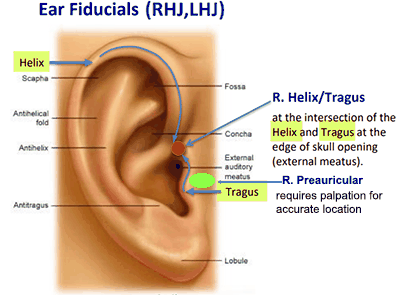

- **Pre-auricular point** (green): just in front of the ear, at the root of the upper edge of the
  cheekbone (zygomatic arch). It is found by feeling for it, so it is harder to place exactly.
- **Helix/tragus intersection** (red): where the helix meets the tragus, at the edge of the ear canal
  opening. It is easy to see on both the scan and the MRI.

> **There is no MEG-lab standard yet.** We don't have enough experience to recommend one of the two. Choose
> one **early, at the cREG step** (when the operator marks the fiducials on the EinScan scans after
> data collection), use it for **every participant and session of the study**, and set `EAR_FIDUCIAL` in
> Step 1 to match.

Here you mark the **same three spots on the MRI scalp** that were marked on the EinScan scan. They give the
fit in Step 5 its starting position, so the ear points must be on the **same landmark** as the scan's: if the
scan used the helix/tragus point but the MRI uses the pre-auricular point, the fit starts several
millimetres off. (Step 4 checks for this.)

### Two ways to place them

**In this notebook (`FIDUCIAL_GUI = "notebook"`, the default).** MNE's coregistration window opens inside
this notebook: it is drawn on scotty and shown in your browser, and the fiducials you save go straight into the
subject's FreeSurfer folder. Over the SSH tunnel this needs the `jupyter-server-proxy` package in the
`pygers-meg` environment (install once, then restart Jupyter):

```
conda activate pygers-meg
pip install jupyter-server-proxy
```

A yellow `bad X server connection` warning when the window opens is normal (scotty has no screen) and can
be ignored. The buttons are the same as on the Mac, in a panel you can fold open on the left.

> **If the 3D view stays blank:**
> - **The log below the window shows `LineTooLong` ("Got more than 8190 bytes")**: your browser is sending
>   too many old Jupyter login cookies (one is saved per port). Get the current `scotty-jupyter` script from the
>   pygers-meg repo: it uses the same port every time and opens Jupyter at `localhost`, which avoids this.
>   If you start Jupyter another way, open it at `http://localhost:<port>/lab` rather than `127.0.0.1`, or
>   delete your browser's cookies for `127.0.0.1`.
> - **The notebook printed a note that `jupyter-server-proxy` is not installed**: install it (above).
> - **Still blank**: use your Mac instead (set `FIDUCIAL_GUI = "mac"` in Step 1 and rerun Step 3).

**On your Mac (`FIDUCIAL_GUI = "mac"`).** The same window runs on your Mac. It opens the FreeSurfer files and
the MEG file directly through the mounted lab partition, and the fiducials you save go straight into the
subject's FreeSurfer folder on the cluster.

The next cell checks whether the fiducials have been saved. **If not, it shows you how to place them and
stops** (with a ⏸ message, not an error).

- **In this notebook:** place and save them in the window that opens, then click in the Step 4 cell and choose
  *Run → Run Selected Cell and All Below*. There's no need to start again from the top.
- **Mac:** place and save them on your Mac, then come back here and run the notebook again from the top.

In [ ]:
def mac_path(path):
    # The same file as your Mac sees it, e.g. /jukebox/pinsk/... -> /Volumes/pinsk/...
    text = str(path)
    if text.startswith(CLUSTER_PATH_PREFIX):
        return MAC_PATH_PREFIX + text[len(CLUSTER_PATH_PREFIX):]
    return text   # unknown prefix: shown as it is (replace the start by hand)


# The command that opens MNE's coregistration window with this subject's MRI and this session's scan
gui_command = (f'mne coreg -d "{mac_path(subjects_dir)}" -s {fs_subject} '
               f'-f "{mac_path(meg_file)}"')

if fiducials_file.is_file():
    saved = datetime.fromtimestamp(fiducials_file.stat().st_mtime).strftime("%Y-%m-%d %H:%M")
    print(f"Found the MRI fiducials (saved {saved}):\n  {fiducials_file}")
    print("\nStep 4 checks them. If you need to re-place them, open the window again with:\n")
    print("  " + gui_command)
else:
    # Python 3.11 can't nest these quotes inside the f-string below, so the sentence is made first
    where = ("Place them in the window below (FIDUCIAL_GUI = 'notebook'), using steps 3-6 of these "
             "instructions." if FIDUCIAL_GUI == "notebook" else "Place them on your Mac:")
    print(f'''
No MRI fiducials yet for {fs_subject}. Ear landmark for this study: {ear_name} (EAR_FIDUCIAL).
{where}

 1. Open the Terminal app on your Mac and activate a conda environment that has MNE-Python
    (with its 3D parts), for example:
        conda activate pygers-meg

 2. Open the coregistration window (one line):

        {gui_command}

    If the path does not start with {MAC_PATH_PREFIX}, replace its start with how your Mac sees the lab partition.

 3. In the left panel, under "MRI Fiducials":
      - make sure "Lock fiducials" is NOT ticked
      - choose LPA, then click the {ear_name} on the LEFT side of the MRI head
      - choose Nasion, then click the nasion
      - choose RPA, then click the {ear_name} on the RIGHT side
    The window starts with rough guesses from a template brain: move ALL three.
    Turn the head with the mouse and zoom in to place each point accurately.
    The coloured points from the EinScan scan are only roughly placed at this stage: ignore them.

 4. Tick "Lock fiducials", then click "Save MRI Fid.". This saves
        {mac_path(fiducials_file)}

 5. Close the window. Do NOT use "Fit ICP", the scaling options or "Save..." in the right panel:
    this notebook does the fit in Step 5.

 6. Come back here and run this notebook again from the top.
''')
    if FIDUCIAL_GUI == "notebook":
        # Open MNE's coregistration window inside this notebook. The 3D view is drawn on scotty (by VTK)
        # and sent to your browser by "trame". Over an SSH tunnel it must go through Jupyter's own
        # port, which is what jupyter-server-proxy does.
        import importlib.util
        import pyvista
        if importlib.util.find_spec("jupyter_server_proxy") is not None:
            pyvista.global_theme.trame.server_proxy_enabled = True
            pyvista.global_theme.trame.server_proxy_prefix = "/proxy/"
        else:
            print("NOTE: jupyter-server-proxy is not installed, so the 3D view will probably stay blank over\\n"
                  "the SSH tunnel. Install it (see Step 3's text) or use FIDUCIAL_GUI = 'mac'.\\n")
        mne.viz.set_3d_backend("notebook")
        coreg_window = mne.gui.coregistration(subject=fs_subject, subjects_dir=str(subjects_dir),
                                              inst=str(meg_file), block=False, verbose=False)
        print("If the 3D view stays blank, see 'If the 3D view stays blank' in Step 3's text above.")
        raise StopHere("Place the MRI fiducials in the window above, tick 'Lock fiducials' and click "
                       "'Save MRI Fid.'. Then click in the Step 4 cell and choose "
                       "Run -> Run Selected Cell and All Below.")
    raise StopHere("Place the MRI fiducials on your Mac (instructions above), "
                   "then run the notebook again from the top.")

## Step 4: Check the fiducials

A misplaced fiducial is easy to miss, so this cell runs a few checks:

- the file has exactly one nasion, one LPA and one RPA, in MRI coordinates;
- **left is left**: LPA is on the left of RPA, and the nasion is in front of the ears;
- the points were **actually moved** from the window's starting guesses (a template estimate). The template is
  used *only* for this check, never for the fit;
- each point is **on the scalp**;
- the distance between the two ear points on the MRI is **similar to the EinScan one**. A big difference
  usually means the MRI points and the operator's marks are on different landmarks (for example the
  helix/tragus intersection on one and the pre-auricular point on the other).

Errors stop the notebook. Warnings let it continue but are worth a look; to fix a point, open the window
again with the command from Step 3, move the point, and save.

In [ ]:
if not fiducials_file.is_file():
    raise StopHere(f"No fiducials saved yet ({fiducials_file.name} is not in {fs_bem_dir}). "
                   "Click 'Save MRI Fid.' in the window in Step 3 (after ticking 'Lock fiducials'), "
                   "then run this cell again.")
mri_fids, coord_frame = mne.io.read_fiducials(fiducials_file)
errors, warnings = [], []

if coord_frame != FIFF.FIFFV_COORD_MRI:
    errors.append("The fiducials are not in MRI coordinates. Save them again with 'Save MRI Fid.' (Step 3).")
idents = [int(f["ident"]) for f in mri_fids]
if sorted(idents) != [FIFF.FIFFV_POINT_LPA, FIFF.FIFFV_POINT_NASION, FIFF.FIFFV_POINT_RPA]:
    errors.append(f"The fiducials file should hold exactly one LPA, nasion and RPA; it holds {idents}.")

if not errors:
    fid_mm = {names[int(f["ident"])]: 1000 * np.asarray(f["r"]) for f in mri_fids}   # metres -> mm
    lpa, nas, rpa = fid_mm["LPA"], fid_mm["nasion"], fid_mm["RPA"]

    # In MRI (FreeSurfer surface RAS) coordinates: x points right, y to the front, z up.
    if lpa[0] >= rpa[0]:
        errors.append("LPA is to the RIGHT of RPA: the two ear points look swapped.")
    ear_mid = (lpa + rpa) / 2
    if nas[1] <= ear_mid[1] + 40:
        errors.append("The nasion is not clearly in front of the ears. Is it placed on the face?")
    mri_ear_distance_mm = np.linalg.norm(lpa - rpa)
    if not 100 <= mri_ear_distance_mm <= 190:
        errors.append(f"LPA-RPA distance is {mri_ear_distance_mm:.0f} mm (a head is about 130-160 mm).")

    # Were the points moved from the window's starting guesses (the template estimate)?
    template = {names[int(f["ident"])]: 1000 * np.asarray(f["r"])
                for f in mne.coreg.get_mni_fiducials(fs_subject, subjects_dir)}
    moved_mm = {n: np.linalg.norm(fid_mm[n] - template[n]) for n in fid_mm}
    not_moved = [n for n, d in moved_mm.items() if d < 1.0]
    if len(not_moved) == 3:
        errors.append("All three fiducials are exactly at the window's starting guesses: they were saved "
                      "without being placed. Place them (Step 3) and save again.")
    elif not_moved:
        warnings.append(f"{', '.join(not_moved)} is still at the window's starting guess. Was it placed?")
    far = [f"{n} ({d:.0f} mm)" for n, d in moved_mm.items() if d > 25]
    if far:
        warnings.append("Far from where a template head would put them: " + ", ".join(far)
                        + ". That can be fine for an unusual head, but check those points.")

    # Is each point on the scalp? (distance to the nearest point of the high-resolution scalp surface)
    scalp = mne.read_bem_surfaces(fs_bem_dir / f"{fs_subject}-head-dense.fif", verbose=False)[0]
    scalp_tree = cKDTree(scalp["rr"] * 1000)
    off_scalp = {n: scalp_tree.query(p)[0] for n, p in fid_mm.items()}
    bad = [f"{n} ({d:.1f} mm)" for n, d in off_scalp.items() if d > 4]
    if bad:
        warnings.append("Not on the scalp surface: " + ", ".join(bad))

    # Same landmarks as the operator's? Compare the ear-to-ear distances.
    ear_diff = mri_ear_distance_mm - dig_ear_distance_mm
    if abs(ear_diff) > 8:
        warnings.append(f"LPA-RPA is {mri_ear_distance_mm:.0f} mm on the MRI but {dig_ear_distance_mm:.0f} mm "
                        f"on the EinScan scan. Are both on the same landmark ({ear_name})?")

    print(f"{'':8s} {'x':>7s} {'y':>7s} {'z':>7s}   moved from start   off scalp")
    for n in ["LPA", "nasion", "RPA"]:
        x, y, z = fid_mm[n]
        print(f"{n:8s} {x:7.1f} {y:7.1f} {z:7.1f}   {moved_mm[n]:9.1f} mm     {off_scalp[n]:5.1f} mm")
    print(f"\nLPA-RPA distance: MRI {mri_ear_distance_mm:.0f} mm, EinScan {dig_ear_distance_mm:.0f} mm")

for w in warnings:
    print("WARNING:", w)
if errors:
    raise RuntimeError("The MRI fiducials need fixing (re-open the window with the command in Step 3):\n- "
                       + "\n- ".join(errors))
print("\nFiducials OK." if not warnings else "\nFiducials usable, but see the warnings above.")

## Step 5: Fit the head shape to the MRI

> **In short: how this notebook gets the best coregistration (Steps 5 and 5b)**
>
> We drop head-shape points below the chin line (`HSP_KEEP_ABOVE_MM`), then fit the full head shape 17 times,
> with hair growth from 0 to 16 mm (`HAIR_SCAN_MM`). We keep the value where the points sit closest to where
> they should be, taking the middle value if several tie. We also fit once using only the upper face, with no
> hair growth. If that face fit has enough face points (at least 2,000, `FACE_FIT_MIN_POINTS`) sitting close to
> the scalp (median 1.5 mm or less, `FACE_FIT_MAX_MEDIAN_MM`), and the two fits would move some OPM sensor by
> 5 mm or more (`COREG_DISAGREE_MM`), we use the face fit; otherwise
> we use the full fit (`COREG_FIT = "auto"`; set it to `"face"` or `"full"` in Step 1 to choose yourself).
> Each fit lines up the fiducials, runs ICP, leaves out points more than 5 mm off and runs ICP again, and
> never scales the MRI.
>
> The rest of this step and Step 5b explain each part.

### How the fit works

The fit moves the EinScan head shape until it lies on the MRI scalp. It only **rotates and shifts**
(6 numbers: 3 rotations, 3 shifts); the head is never stretched. It runs in three stages, as in MNE's
[automated coregistration tutorial](https://mne.tools/stable/auto_tutorials/forward/25_automated_coreg.html):

1. **Fiducials only.** Line up the three EinScan fiducials with the three you placed on the MRI. This gives
   a rough starting position.
2. **First ICP fit.** ICP ("iterative closest point") pairs every head-shape point with the nearest point on
   the MRI scalp, moves the head shape to bring the pairs closer, and repeats. The nasion also takes part,
   weighted by `NASION_WEIGHT`, which stops the head shape from sliding up or down.
3. **Drop stray points and fit again.** Points that are still more than `OMIT_DISTANCE_MM` from the scalp
   after the first fit are left out (stray points from the chin rest, shoulders, or wrinkles in the cap), and
   the fit is run again.

### Leaving out the chin and neck: `HSP_KEEP_ABOVE_MM`

The fit only uses head-shape points **above** `HSP_KEEP_ABOVE_MM` (default -40 mm, measured from the plane
through the nasion and the two ear points; Step 2 left the others out). That keeps the forehead, brow, eyes,
nose, upper cheeks, temples and the whole cap, and drops the mouth, chin, jaw, neck and the lowest part of the
back of the head. Those parts don't help:

- **They move.** Mouth, jaw and neck posture differ between the MRI and the EinScan session (chin rest, collar,
  swallowing), so they don't match the MRI even when the head itself is perfectly aligned.
- **The MRI may not cover them.** The MRI often stops around the chin, and FreeSurfer closes the bottom of the
  scalp surface with a made-up flat cap, so neck points have nothing real to match.
- **They would count as "face".** MNE's hair rule puts everything below the cap on the "face" side, so they would
  also disturb the hair-growth choice below.

The nose and brow are the important face points: they hold the fit in place while the hair growth varies. If
Step 6 warns about too few face points, lower the cut (for example -60) or set it to `None` to keep every point.
In Step 7 the points left out are drawn in grey, so you can see where the cut falls.

> **No scaling.** MNE can also stretch the MRI to fit the head shape. That is meant for when there is no
> MRI of the participant and a template head is used instead. With the participant's own MRI the head
> already has the right size, so scaling would only make the fit worse. This notebook never scales.

### The swim cap: `HAIR_GROW_MM`

In the MEG lab, the EinScan scan is taken with a **swim cap over the hair**. Over the hair, the scan
therefore sees the outside of the cap, which sits a few millimetres *outside* the scalp that the MRI shows.
On the face (no cap, no hair) the scan sees the skin itself.

The **hair growth** tells the fit how big that gap is. MNE moves the MRI scalp outwards by this amount
**only over the hair-covered part of the head** (MNE's rule: points higher up than they are far forward,
so the top, back and upper sides of the head, but not the face). Without it, the fit would pull the head
down into the cap, and the error would show up as a shift of the whole head.

The gap is mostly squashed hair, so it varies from person to person (roughly 0-2 mm for very short hair,
3-5 mm for short to medium, 5-8 mm or more for long or thick hair, and more again if the cap sits loosely).
Rather than guess, **the notebook measures it**:

- **`HAIR_GROW_MM = "auto"` (the default):** the cell below runs the whole three-stage fit once for every
  value in `HAIR_SCAN_MM` (0, 1, 2, ... 16 mm) and keeps the value whose fit puts the face points *and* the cap
  points closest to where they should be (the smallest median fit error, explained in Step 6). The fit for
  that value is the result; nothing is fitted again.
- **`HAIR_GROW_MM = 6.0` (any number):** that exact value is used. The other values are still tried as a
  check (set `HAIR_SCAN_MM = None` to skip that), and Step 6 tells you if one fits clearly better.

> **Why repeat the whole fit, instead of fitting once and measuring the gap?** If the hair growth is too small,
> the fit doesn't leave the cap points sticking out: it shifts and tilts the whole head into the cap a little
> instead, and pushes the face out. Measured after such a fit, the gap looks smaller than it is. Repeating the
> fit for each value avoids that: the right value is the one where face *and* cap fit together.

**How the value is chosen, and when you get a warning:**

- **Several values fit almost equally well** (within `FLAT_TOLERANCE_MM` of the best): the middle one of them
  is used, so the same participant doesn't flip between, say, 4 and 5 mm from one session to the next on
  noise alone. If many values are that close, the gap is poorly determined and Step 6 warns you.
- **The best value is at the end of the range** (0 or 16 mm): the right value may lie outside it, so Step 6
  warns you to extend `HAIR_SCAN_MM`.
- **Few face points** (fewer than `MIN_FACE_POINTS`): the face is what holds the fit in place while the hair
  growth changes, so with too few face points the choice is less reliable.
- **A large value** (more than about 8-10 mm) can be real (a loose cap, very thick hair), but it can also mean
  the fit is using the hair growth to absorb something else, such as stray points or a wrinkled cap. Look
  at the pictures in Step 7: the cap points should sit evenly over the scalp.

Trying 17 values takes a while with a dense EinScan scan (each fit uses every head-shape point), so this
cell can take a few minutes.

In [ ]:
# ---- MRI scalp with outward-pointing normals (used to measure distances to the scalp) ----------
scalp_rr = scalp["rr"] * 1000                       # scalp vertices (mm), loaded in Step 4
tri = scalp["tris"]
face_normals = np.cross(scalp_rr[tri[:, 1]] - scalp_rr[tri[:, 0]], scalp_rr[tri[:, 2]] - scalp_rr[tri[:, 0]])
vertex_normals = np.zeros_like(scalp_rr)
for k in range(3):                                  # each vertex: sum of the normals of its triangles
    np.add.at(vertex_normals, tri[:, k], face_normals)
vertex_normals /= np.linalg.norm(vertex_normals, axis=1, keepdims=True)
if np.mean(np.sum(vertex_normals * (scalp_rr - scalp_rr.mean(0)), axis=1)) < 0:
    vertex_normals *= -1                            # make them point out of the head


def run_fit(hair_mm):
    # The three-stage fit described above, for one hair-growth value. Returns the fitted
    # Coregistration and the distances after each stage.

    def summary():
        # Distances (mm) from the points used in the fit to the (hair-grown) MRI scalp
        d = coreg.compute_dig_mri_distances() * 1000
        return {"MeanMm": float(d.mean()), "MedianMm": float(np.median(d)), "MaxMm": float(d.max()),
                "NumberOfPoints": int(len(d))}

    # Use YOUR fiducials (never the template estimate), and never stretch the MRI
    coreg = mne.coreg.Coregistration(info_fit, fs_subject, subjects_dir, fiducials=mri_fids)
    coreg.set_scale_mode(None)
    stages = {}
    # Stage 1: fiducials only
    coreg.fit_fiducials(verbose=False)
    stages["fiducials"] = summary()
    # Stage 2: first ICP fit, with the cap correction
    coreg.set_grow_hair(hair_mm)
    coreg.fit_icp(n_iterations=ICP_ITERATIONS[0], nasion_weight=NASION_WEIGHT, verbose=False)
    stages["first_icp"] = summary()
    # Stage 3: leave out stray points, then fit again
    coreg.omit_head_shape_points(distance=OMIT_DISTANCE_MM / 1000)   # MNE wants metres
    stages["left_out"] = stages["first_icp"]["NumberOfPoints"] - len(coreg.compute_dig_mri_distances())
    coreg.fit_icp(n_iterations=ICP_ITERATIONS[1], nasion_weight=NASION_WEIGHT, verbose=False)
    stages["final"] = summary()
    return coreg, stages


def point_errors(trans, hair_mm, pts=None):
    # For every head-shape point used (or the points given): position on the MRI (mm), signed distance to the
    # bare MRI scalp (+ = outside), whether it is under the cap, and its fit error (distance from where it
    # should be: 0 mm for face points, hair_mm for cap points)
    xyz = 1000 * apply_trans(trans, hsp if pts is None else pts)
    _, nearest = scalp_tree.query(xyz)               # nearest scalp vertex for each point
    signed = np.sum((xyz - scalp_rr[nearest]) * vertex_normals[nearest], axis=1)
    cap_point = xyz[:, 2] > xyz[:, 1]                # MNE's hair rule: higher up than forward
    error = signed - np.where(cap_point, hair_mm, 0.0)
    return xyz, signed, cap_point, error


# ---- Check the setting ---------------------------------------------------------------------------
auto_hair = isinstance(HAIR_GROW_MM, str)
if auto_hair and HAIR_GROW_MM != "auto":
    raise ValueError(f'HAIR_GROW_MM must be "auto" or a number (mm), not {HAIR_GROW_MM!r}')
if auto_hair and not HAIR_SCAN_MM:
    raise ValueError('HAIR_GROW_MM = "auto" needs a list of values in HAIR_SCAN_MM to try.')
scan_values = sorted({float(h) for h in (HAIR_SCAN_MM or [])})

# ---- Run the fit for every value to try ----------------------------------------------------------
fits = {}        # hair growth (mm) -> (fitted Coregistration, distances after each stage)
hair_scan = {}   # hair growth (mm) -> median fit error (mm)
if scan_values:
    print(f"Fitting with hair growth {scan_values[0]:g} to {scan_values[-1]:g} mm "
          f"({len(scan_values)} fits; this can take a few minutes) ...")
    for h in scan_values:
        fits[h] = run_fit(h)
        hair_scan[h] = float(np.median(np.abs(point_errors(fits[h][0].trans, h)[3])))
    print("  hair growth (mm):" + "".join(f"{h:6g}" for h in hair_scan))
    print("  median error (mm):" + "".join(f"{e:6.2f}" for e in hair_scan.values()))
    best_hair = min(hair_scan, key=hair_scan.get)
    # All values that fit almost as well as the best one; "auto" uses the middle one of them
    # (with an even number of them, the better-fitting of the two in the middle)
    near_best = [h for h in scan_values if hair_scan[h] <= hair_scan[best_hair] + FLAT_TOLERANCE_MM]
    middle_two = {near_best[(len(near_best) - 1) // 2], near_best[len(near_best) // 2]}
    middle_of_near = min(middle_two, key=hair_scan.get)
else:
    best_hair, near_best, middle_of_near = None, [], None

# ---- The value used ------------------------------------------------------------------------------
if auto_hair:
    hair_used = middle_of_near
    how = (f"best of {len(scan_values)}" if len(near_best) == 1 else
           f"middle of {len(near_best)} values within {FLAT_TOLERANCE_MM} mm of the best "
           f"({near_best[0]:g}-{near_best[-1]:g} mm)")
    print(f"\nHair growth used: {hair_used:g} mm (auto: {how})")
else:
    hair_used = float(HAIR_GROW_MM)
    if hair_used not in fits:
        fits[hair_used] = run_fit(hair_used)
    print(f"\nHair growth used: {hair_used:g} mm (set in Step 1)")

coreg, stages = fits[hair_used]
head_mri_t = coreg.trans    # the result: the head -> MRI transform
n_left_out = stages["left_out"]

# How the fit with that value went, stage by stage (distances to the hair-grown scalp)
for label, key in [("1. after fiducial fit:", "fiducials"), ("2. after first ICP fit:", "first_icp"),
                   ("3. after final ICP fit:", "final")]:
    d = stages[key]
    print(f"  {label:26s} mean {d['MeanMm']:5.2f}  median {d['MedianMm']:5.2f}  max {d['MaxMm']:6.2f} mm"
          f"   ({d['NumberOfPoints']} points incl. fiducials)")
    if key == "first_icp":
        print(f"     left out {n_left_out} of the {len(hsp)} head-shape points used "
              f"(further than {OMIT_DISTANCE_MM} mm)")

# How far each EinScan fiducial ends up from the MRI fiducial you placed
dig_fid_mri_mm = {n: 1000 * apply_trans(head_mri_t, cardinal[k]) for k, n in names.items()}
fid_error_mm = {n: float(np.linalg.norm(dig_fid_mri_mm[n] - fid_mm[n])) for n in fid_mm}
print("\nEinScan fiducial -> MRI fiducial after the fit: "
      + ", ".join(f"{n} {d:.1f} mm" for n, d in fid_error_mm.items()))

## Step 5b: Face-only fit, and which fit to use

The fit in Step 5 uses the whole head shape, with the cap modelled as a **uniform shell** (`HAIR_GROW_MM`) over
everything above MNE's 45° hair line. Real hair under a cap is not uniform: it is thick at the crown and back,
thin at the temples, and a bun, braid or wrinkle makes a bump. MNE's hair line is also only a tilted plane, so the
upper forehead can end up on the "hair" side and the nape on the "face" side. An uneven cap can **tilt or
shift** the fit, not just add error.

The face has no hair and no cap, so this cell fits again with **only the face points**: points in front of the ears
(`FACE_MIN_FORWARD_MM`), below the brow (`FACE_MAX_HEIGHT_MM`) and above the chin cut (`HSP_KEEP_ABOVE_MM`), all
measured in head coordinates, with no hair growth. It reports:

- **How much the two fits disagree**, as the distance each OPM sensor (and the middle of the brain) would move
  relative to the MRI between the two fits. This is what matters for the forward model.
  Under about 2 mm: the cap is not biasing the fit. 2-5 mm: worth a look. Over 5 mm: the cap is pulling the
  full fit.
- **A cap-gap map**: with the head placed by the face alone, how far the cap sits outside the bare scalp in each
  region (front, top, back, left, right). That shows how uneven the layer under the cap is, which can tell the
  MEG operators what to change (cap size, hair under the cap).

### Which fit is used: `COREG_FIT`

- **`"auto"` (the default):** the **face-only fit** is used when it is trustworthy *and* the two fits disagree;
  otherwise the **full fit**. Trustworthy means at least `FACE_FIT_MIN_POINTS` face points sitting close to the
  scalp (median distance at most `FACE_FIT_MAX_MEDIAN_MM`). Disagree means an OPM sensor moves at least
  `COREG_DISAGREE_MM` between the fits. When the cap is even, the two fits agree and the full fit is kept: it
  covers the whole head, so it pins down rotation best. When the cap is uneven, the face takes over.
- **`"full"`:** always the full fit (the face-only fit is still run and reported, unless `FACE_CHECK = False`).
- **`"face"`:** always the face-only fit.

Everything after this cell uses the fit chosen here: the quality numbers (Step 6), the pictures (Step 7), the saved
transform and T1w landmarks (Step 8) and the forward model (Part 2). The report records which fit was used and why.

In [ ]:
# ---- Check the setting ---------------------------------------------------------------------------
if COREG_FIT not in ("auto", "full", "face"):
    raise ValueError(f'COREG_FIT must be "auto", "full" or "face", not {COREG_FIT!r}')

# ---- Which points are face points (head coordinates: x to the right ear, y to the nose, z up; mm) ---
hsp_mm = hsp * 1000                                   # the points used in the fit (chin and neck already cut)
is_face_pt = (hsp_mm[:, 1] > FACE_MIN_FORWARD_MM) & (hsp_mm[:, 2] < FACE_MAX_HEIGHT_MM)
face_check = None                                     # filled in below (saved in the report in Step 8)
face_notes = []                                       # notes for Step 6's list
fig_face = None
full_t = head_mri_t                                   # the full fit from Step 5
face_t = None

if not FACE_CHECK and COREG_FIT == "full":
    print('FACE_CHECK = False and COREG_FIT = "full": face-only fit skipped.')
elif is_face_pt.sum() < 100:
    print(f"Only {int(is_face_pt.sum())} face points (in front of y = {FACE_MIN_FORWARD_MM} mm and below "
          f"z = {FACE_MAX_HEIGHT_MM} mm): too few for a face-only fit, so it was skipped. Is the face "
          "in the EinScan scan?")
else:
    # ---- Fit with the face points only, no hair growth --------------------------------------------
    info_face = info.copy()
    with info_face._unlock():   # keep the fiducials and the face points; drop every other head-shape point
        info_face["dig"] = [d for d in dig if d["kind"] != FIFF.FIFFV_POINT_EXTRA
                            or (d["r"][1] * 1000 > FACE_MIN_FORWARD_MM and d["r"][2] * 1000 < FACE_MAX_HEIGHT_MM
                                and (HSP_KEEP_ABOVE_MM is None or d["r"][2] * 1000 > HSP_KEEP_ABOVE_MM))]
    face_coreg = mne.coreg.Coregistration(info_face, fs_subject, subjects_dir, fiducials=mri_fids)
    face_coreg.set_scale_mode(None)
    face_coreg.fit_fiducials(verbose=False)
    face_coreg.fit_icp(n_iterations=ICP_ITERATIONS[0], nasion_weight=NASION_WEIGHT, verbose=False)
    face_coreg.omit_head_shape_points(distance=OMIT_DISTANCE_MM / 1000)
    face_coreg.fit_icp(n_iterations=ICP_ITERATIONS[1], nasion_weight=NASION_WEIGHT, verbose=False)
    face_t = face_coreg.trans

    # ---- How much the two fits disagree --------------------------------------------------------------
    # Sensor positions in head coordinates, then into the MRI with each transform
    sens_head = apply_trans(info["dev_head_t"], np.array([info["chs"][i]["loc"][:3] for i in meg_picks]))
    shift_sens = 1000 * np.linalg.norm(apply_trans(face_t, sens_head) - apply_trans(full_t, sens_head), axis=1)
    # The middle of the brain (centre of the inner skull surface), from MRI back to head with the full fit
    inner = mne.read_surface(fs_bem_dir / "inner_skull.surf")[0] / 1000      # mm -> m, MRI coordinates
    brain_head = apply_trans(np.linalg.inv(full_t["trans"]), inner.mean(axis=0))
    shift_brain = 1000 * np.linalg.norm(apply_trans(face_t, brain_head) - apply_trans(full_t, brain_head))
    rel = np.linalg.inv(full_t["trans"]) @ face_t["trans"]                 # face fit relative to full fit
    angle = np.degrees(np.arccos(np.clip((np.trace(rel[:3, :3]) - 1) / 2, -1, 1)))
    biggest = float(shift_sens.max())

    # ---- Face points and the cap, with the head placed by the face alone -----------------------------
    _, signed_face_fit, _, _ = point_errors(face_t, 0.0)                    # distance to the bare scalp
    face_resid = signed_face_fit[is_face_pt]
    face_median_abs = float(np.median(np.abs(face_resid)))
    # Cap points: everything above the ear-nasion plane that is not a face point, sorted into regions
    above = (hsp_mm[:, 2] > 0) & ~is_face_pt
    elev_deg = np.degrees(np.arctan2(hsp_mm[:, 2], np.hypot(hsp_mm[:, 0], hsp_mm[:, 1])))
    azim_deg = np.degrees(np.arctan2(hsp_mm[:, 1], hsp_mm[:, 0]))           # 90 = front, 0 = right
    region = np.where(elev_deg > 55, "top",
             np.where((azim_deg > 45) & (azim_deg <= 135), "front",
             np.where((azim_deg > -45) & (azim_deg <= 45), "right",
             np.where((azim_deg > -135) & (azim_deg <= -45), "back", "left"))))
    gap_rows = []
    for r in ["front", "top", "left", "right", "back"]:
        sel = above & (region == r)
        if sel.sum() >= 20:
            q1, med, q3 = np.percentile(signed_face_fit[sel], [25, 50, 75])
            gap_rows.append({"region": r, "points": int(sel.sum()), "median_gap_mm": round(float(med), 1),
                             "middle_half_mm": f"{q1:.1f} to {q3:.1f}"})
    gap_table = pd.DataFrame(gap_rows)

    print(f"Face-only fit: {int(is_face_pt.sum())} face points; they sit {np.median(face_resid):+.2f} mm from the "
          f"scalp (median), {face_median_abs:.2f} mm median distance")
    print(f"\nFull fit vs face-only fit: rotation {angle:.1f} deg")
    print(f"  OPM sensors would move: median {np.median(shift_sens):.1f} mm, largest {biggest:.1f} mm")
    print(f"  middle of the brain would move: {shift_brain:.1f} mm")
    verdict = ("the fits agree: the cap is not biasing the fit" if biggest < 2 else
               "the fits differ a little: look at the cap-gap map" if biggest < COREG_DISAGREE_MM else
               "the fits disagree: the cap is pulling the full fit")
    print(f"  -> {verdict}")
    print(f"\nCap gap with the head placed by the face (distance outside the bare scalp; "
          f"the full fit used {hair_used:g} mm everywhere):")
    print(gap_table.to_string(index=False))

    face_check = {"FaceMinForwardMm": FACE_MIN_FORWARD_MM, "FaceMaxHeightMm": FACE_MAX_HEIGHT_MM,
                  "NumberOfFacePoints": int(is_face_pt.sum()),
                  "FacePointsMedianSignedMm": round(float(np.median(face_resid)), 2),
                  "FacePointsMedianDistanceMm": round(face_median_abs, 2),
                  "RotationDeg": round(float(angle), 2),
                  "SensorShiftMedianMm": round(float(np.median(shift_sens)), 2),
                  "SensorShiftMaxMm": round(biggest, 2), "BrainCentreShiftMm": round(float(shift_brain), 2),
                  "Verdict": verdict, "CapGapByRegion": gap_rows,
                  "FaceOnlyTransform": face_t["trans"].tolist()}

    # ---- Pictures: the cap gap and the face points, with the head placed by the face ----------------
    xyz_face_fit = 1000 * apply_trans(face_t, hsp)                          # MRI coordinates (mm)
    head_med = mne.read_bem_surfaces(fs_bem_dir / f"{fs_subject}-head-medium.fif", on_defects="ignore",
                                     verbose=False)[0]
    v, tr = head_med["rr"] * 1000, head_med["tris"]
    ctr = v.mean(axis=0)
    fig = plt.figure(figsize=(16, 5.5))
    for k, (title, el, az) in enumerate([("Front", 0, 90), ("Left", 0, 180), ("Back", 0, -90), ("Top", 90, -90)], 1):
        ax = fig.add_subplot(1, 4, k, projection="3d", computed_zorder=False)
        ax.plot_trisurf(v[:, 0], v[:, 1], v[:, 2], triangles=tr, color="#e0b9a0", alpha=0.3, linewidth=0,
                        antialiased=False, shade=True,
                        lightsource=LightSource(azdeg=90 - az + 25, altdeg=min(el + 35, 90)))
        e, a = np.radians(el), np.radians(az)
        side = (xyz_face_fit - ctr) @ np.array([np.cos(e) * np.cos(a), np.cos(e) * np.sin(a), np.sin(e)]) > 0
        sc = ax.scatter(*xyz_face_fit[side].T, c=signed_face_fit[side], cmap="viridis", vmin=-2, vmax=16, s=4,
                        edgecolors="none", depthshade=False)
        ax.view_init(elev=el, azim=az)
        ax.set_box_aspect(np.ptp(v, axis=0), zoom=1.25)
        ax.set_axis_off()
        ax.set_title(title, fontsize=13)
    fig.colorbar(sc, ax=fig.axes, shrink=0.7, label="distance outside the bare scalp (mm)")
    fig.suptitle(f"{base}: head placed by the face alone; colour = cap gap (face points should be ~0)",
                 fontsize=14)
    plt.show()
    fig_face = fig

# ---- Which fit to use ----------------------------------------------------------------------------
face_ok = (face_t is not None and is_face_pt.sum() >= FACE_FIT_MIN_POINTS
           and face_median_abs <= FACE_FIT_MAX_MEDIAN_MM)
if COREG_FIT == "full":
    fit_used, fit_reason = "full", 'COREG_FIT = "full"'
elif COREG_FIT == "face":
    if face_t is None:
        raise RuntimeError('COREG_FIT = "face", but there are too few face points for a face-only fit. '
                           'Use COREG_FIT = "auto" or "full".')
    fit_used, fit_reason = "face", 'COREG_FIT = "face"'
    if not face_ok:
        face_notes.append("the face-only fit is used (COREG_FIT = \"face\") although it is not clearly trustworthy "
                          f"({int(is_face_pt.sum())} face points, median distance {face_median_abs:.2f} mm)")
elif face_t is None:
    fit_used, fit_reason = "full", "auto: no face-only fit (too few face points)"
elif not face_ok:
    fit_used, fit_reason = "full", (f"auto: the face-only fit is not trustworthy enough ({int(is_face_pt.sum())} "
                                    f"face points, median distance {face_median_abs:.2f} mm; needs at least "
                                    f"{FACE_FIT_MIN_POINTS} points and at most {FACE_FIT_MAX_MEDIAN_MM} mm)")
elif biggest < COREG_DISAGREE_MM:
    fit_used, fit_reason = "full", (f"auto: the fits agree (sensors move at most {biggest:.1f} mm, "
                                    f"under {COREG_DISAGREE_MM} mm)")
else:
    fit_used, fit_reason = "face", (f"auto: the fits disagree (sensors move up to {biggest:.1f} mm) and the "
                                    "face-only fit is trustworthy")

if face_t is not None and fit_used == "full" and biggest >= COREG_DISAGREE_MM:
    face_notes.append(f"the full fit is used, but the face-only fit puts the OPM sensors up to {biggest:.1f} mm away "
                      "(Step 5b): the cap may be biasing it")

# Everything from here on uses this fit
head_mri_t = face_t if fit_used == "face" else full_t
fit_label = "face-only fit" if fit_used == "face" else f"full fit (hair growth {hair_used:g} mm)"
dig_fid_mri_mm = {n: 1000 * apply_trans(head_mri_t, cardinal[k]) for k, n in names.items()}
fid_error_mm = {n: float(np.linalg.norm(dig_fid_mri_mm[n] - fid_mm[n])) for n in fid_mm}
print(f"\n>>> Fit used from here on: {fit_label}")
print(f"    why: {fit_reason}")
print("    EinScan fiducial -> MRI fiducial: " + ", ".join(f"{n} {d:.1f} mm" for n, d in fid_error_mm.items()))

## Step 6: How good is the fit?

This checks **the fit chosen in Step 5b** (see the line `>>> Fit used from here on` above). It measures, for every
head-shape point, its **signed distance** to the bare MRI scalp (positive = outside the skin, negative = inside),
and judges it by the model that fit was made with:

**Full fit** (whole head, uniform hair growth):

- **Face points** (MNE's hair rule: below its 45° hair line) should sit on the scalp, close to 0 mm.
- **Cap points** (above the line) should sit about the hair growth outside the scalp.
- The **fit error** is how far each point is from that. A good OPM coregistration has a median of about 1-2 mm.

**Face-only fit** (no hair growth):

- **Face points** (the face from Step 5b) should sit on the scalp: their median distance is the fit error.
- **Cap points** have no target: the cap can sit anywhere from on the scalp to well outside it, and Step 5b has
  already shown how the gap varies by region. They only count as "far" where their position is impossible:
  more than `CAP_INSIDE_MM` *inside* the skin, or more than `CAP_MAX_GAP_MM` outside it. A cluster of those means
  the head is misplaced in that region.

It also reports the **fiducial check** (how far each EinScan fiducial lands from your MRI fiducial: a few mm is
normal; more than about 10 mm suggests a fiducial was placed on a different landmark) and, for the full fit,
**warnings about the hair-growth choice** (see the end of Step 5).

In [ ]:
# ---- Every head-shape point: distance to the bare MRI scalp, with the fit chosen in Step 5b ---------
# (the table has every point, including the ones cut below HSP_KEEP_ABOVE_MM; the numbers use the points used)
all_mri, all_signed, all_cap_mne, _ = point_errors(head_mri_t, hair_used, hsp_all)

if fit_used == "face":
    # Face-only fit: judged by its own model. Face points (the face from Step 5b) should sit on the scalp.
    # Cap points (everything else) can sit anywhere from on the scalp to well outside it, so they only count
    # as "far" where that is impossible: more than CAP_INSIDE_MM inside the skin, or more than CAP_MAX_GAP_MM out.
    all_face = (hsp_all[:, 1] * 1000 > FACE_MIN_FORWARD_MM) & (hsp_all[:, 2] * 1000 < FACE_MAX_HEIGHT_MM)
    all_error = np.where(all_face, all_signed,
                np.where(all_signed < -CAP_INSIDE_MM, all_signed + CAP_INSIDE_MM,       # inside the skin
                np.where(all_signed > CAP_MAX_GAP_MM, all_signed - CAP_MAX_GAP_MM, 0.0)))   # too far out
    all_far = np.where(all_face, np.abs(all_error) > OMIT_DISTANCE_MM, all_error != 0)
else:
    # Full fit: face/cap by MNE's hair rule; cap points should sit the hair growth outside the scalp
    all_face = ~all_cap_mne
    all_error = all_signed - np.where(all_cap_mne, hair_used, 0.0)
    all_far = np.abs(all_error) > OMIT_DISTANCE_MM

points = pd.DataFrame({
    "x_mri_mm": all_mri[:, 0].round(2), "y_mri_mm": all_mri[:, 1].round(2), "z_mri_mm": all_mri[:, 2].round(2),
    "height_head_mm": (hsp_all[:, 2] * 1000).round(2),   # above (+) or below (-) the ear-nasion plane
    "cut": ~keep_hsp,                                     # True: below HSP_KEEP_ABOVE_MM, not used in the fit
    "region": np.where(all_face, "face", "cap"),
    "signed_distance_mm": all_signed.round(2),            # to the bare MRI scalp
    "fit_error_mm": all_error.round(2),                   # how far from where it should be (see above)
    "far": all_far,
})
used = points[~points.cut]
face, cap = used[used.region == "face"], used[used.region == "cap"]
# The points used, as arrays (for the pictures in Step 7)
hsp_mri, error_mm, signed_mm = all_mri[keep_hsp], all_error[keep_hsp], all_signed[keep_hsp]
face_used = all_face[keep_hsp]
face_offset = float(np.median(face.signed_distance_mm[~face.far]))

print(f"Fit checked: {fit_label}")
print(f"Points used: {len(face)} face, {len(cap)} cap"
      + (f"  [{int((~keep_hsp).sum())} below {HSP_KEEP_ABOVE_MM:g} mm not used]" if (~keep_hsp).any() else ""))
if fit_used == "face":
    median_error = float(np.median(np.abs(face.fit_error_mm)))    # face points only: the cap has no target
    far_fraction = float(face.far.mean())
    cap_inside = int((cap.signed_distance_mm < -CAP_INSIDE_MM).sum())
    cap_too_far = int((cap.signed_distance_mm > CAP_MAX_GAP_MM).sum())
    cap_bad_fraction = (cap_inside + cap_too_far) / max(len(cap), 1)
    print(f"Face points: median distance to the scalp {median_error:.2f} mm, median signed {face_offset:+.2f} mm "
          f"(should be ~0); {int(face.far.sum())} more than {OMIT_DISTANCE_MM:g} mm off ({100 * far_fraction:.1f}%)")
    print(f"Cap points : gap outside the scalp median {np.median(cap.signed_distance_mm):+.1f} mm "
          f"(middle half {np.percentile(cap.signed_distance_mm, 25):.1f} to "
          f"{np.percentile(cap.signed_distance_mm, 75):.1f} mm; Step 5b has it by region)")
    print(f"             impossible positions: {cap_inside} more than {CAP_INSIDE_MM:g} mm inside the skin, "
          f"{cap_too_far} more than {CAP_MAX_GAP_MM:g} mm out ({100 * cap_bad_fraction:.1f}%)")
else:
    median_error = float(np.median(np.abs(used.fit_error_mm)))   # all points used (robust to strays)
    far_fraction = float(used.far.mean())
    print(f"{int(used.far.sum())} points far from where they should be ({100 * far_fraction:.1f}%)")
    print(f"Median fit error: {median_error:.2f} mm")
    print(f"  face points: median signed distance {face_offset:+.2f} mm  (should be ~0)")
    print(f"  cap points : median signed distance {np.median(cap.signed_distance_mm[~cap.far]):+.2f} mm"
          f"  (should be ~{hair_used:g}, the hair growth used)")
print("Fiducials  : " + ", ".join(f"{n} {d:.1f} mm" for n, d in fid_error_mm.items()))

# ---- Verdict ------------------------------------------------------------------------------------
qc_notes = list(face_notes)   # notes from Step 5b first
what = "face points' median distance" if fit_used == "face" else "median fit error"
if median_error > QC_MEDIAN_MM:
    qc_notes.append(f"{what} {median_error:.1f} mm is above QC_MEDIAN_MM ({QC_MEDIAN_MM} mm)")
if far_fraction > QC_FAR_FRACTION:
    qc_notes.append(f"{100 * far_fraction:.0f}% of the {'face ' if fit_used == 'face' else ''}points are far from "
                    f"where they should be (QC_FAR_FRACTION = {100 * QC_FAR_FRACTION:.0f}%)")
if fit_used == "face" and cap_bad_fraction > QC_FAR_FRACTION:
    qc_notes.append(f"{100 * cap_bad_fraction:.0f}% of the cap points are in impossible places ({cap_inside} inside "
                    f"the skin, {cap_too_far} too far out): the head may be misplaced there; check Step 7")
if max(fid_error_mm.values()) > 10:
    qc_notes.append("an EinScan fiducial lands more than 10 mm from your MRI fiducial (see Steps 3-4)")
if abs(face_offset) > 2:
    qc_notes.append("the face points sit consistently inside or outside the scalp; check the pictures in Step 7")
# Hair-growth warnings (see the end of Step 5): only about the full fit, so only when it is used
if hair_scan and fit_used == "full":
    if best_hair in (scan_values[0], scan_values[-1]):
        qc_notes.append(f"the best hair growth ({best_hair:g} mm) is at the end of HAIR_SCAN_MM "
                        f"({scan_values[0]:g}-{scan_values[-1]:g} mm): the right value may be outside it, "
                        "so extend HAIR_SCAN_MM")
    if len(near_best) >= 4:
        qc_notes.append(f"{len(near_best)} hair-growth values ({near_best[0]:g}-{near_best[-1]:g} mm) fit almost "
                        "equally well, so the cap gap is poorly determined")
    if not auto_hair and abs(best_hair - hair_used) >= 2:
        qc_notes.append(f"hair growth {best_hair:g} mm fits better than {hair_used:g} mm: use "
                        'HAIR_GROW_MM = "auto" (or that value) in Step 1 and run again with OVERWRITE = True')
    if hair_used > 10:
        qc_notes.append(f"the hair growth used is large ({hair_used:g} mm): check in Step 7 that the cap points sit "
                        "evenly over the scalp (it may be absorbing stray points or a wrinkled cap)")
if len(face) < MIN_FACE_POINTS:
    qc_notes.append(f"only {len(face)} face points (MIN_FACE_POINTS = {MIN_FACE_POINTS}): the face holds the fit "
                    "in place, so the fit is less reliable"
                    + (" (lower HSP_KEEP_ABOVE_MM or set it to None to keep more)" if HSP_KEEP_ABOVE_MM is not None
                       else ""))

print()
if qc_notes:
    print("CHECK THE FIT:\n- " + "\n- ".join(qc_notes))
else:
    print("PASS: the fit looks good. Confirm with the pictures in Step 7.")

## Step 7: Look at the alignment

Numbers can hide problems, so **always look at the pictures.**

These pictures show **the fit chosen in Step 5b** (named in the title), coloured the way Step 6 judges it.
With the **face-only fit**, the face points are coloured by fit error (they should be white) and the cap points by
their gap outside the scalp (a second colour bar); dark purple cap points are inside the skin, which is
impossible, so look for clusters of them. With the **full fit**, every point is coloured by fit error.

**Reading the colours in the full fit.** The colours are the distance from where the fit **expected** each
point to be, not the distance to the scalp. The full fit assumes the cap sits the same distance outside the scalp
everywhere: the hair growth chosen in Step 5. So every cap point is coloured by its actual gap minus that
expected gap:

> colour = (distance outside the bare MRI scalp) − (hair growth used)

The gap isn't really the same everywhere. At the edges of the cap (forehead, temples, above the ears) there is
little or no hair under it and the elastic edge pulls it tight against the skin, so the gap is only a few mm.
On top and at the back, the cap rides over the bulk of the hair and the gap is larger. So with, say, 9 mm of
hair growth:

- a cap-edge point that really sits 2 mm outside the scalp shows as 2 − 9 = **−7 mm (dark blue)**. It is not
  inside the head; it is just closer to the scalp than the uniform 9 mm the fit assumed;
- a point on top that sits 13 mm out shows as **+4 mm (red)**.

A **blue band around the edges of the cap with red on top and at the back is therefore normal** for the full fit:
it is the uniform-cap assumption, not a misplaced head. MNE's hair rule adds to it: everything higher than it is
forward counts as cap, so the upper forehead (bare skin) is expected to sit at the full hair growth too.
Whether the uneven cap actually **pulls the head** out of place is what Step 5b measures (how far the sensors
move between the full and the face-only fit); the face-only fit avoids the assumption altogether.

**3D views.** The MRI scalp is drawn see-through, with:

- **head-shape points**, coloured by fit error: white = where it should be, **red = further out** than
  expected, **blue = further in** than expected (for face points that means inside the skin; for cap points in
  the full fit, closer to the scalp than the hair growth, see above). Only the points on the side facing you are
  drawn;
- **grey points**: head-shape points below `HSP_KEEP_ABOVE_MM` (chin, jaw, neck), left out of the fit;
- **fiducials**: diamonds ◆ = the ones you placed on the MRI, circles ● = the EinScan ones after the fit
  (red = LPA, green = nasion, blue = RPA). Each circle should sit on its diamond;
- **OPM sensors** (black squares), with a short line along each channel's measuring direction.

What to look for:

- the points hug the scalp everywhere, with no large patch of red or blue. A whole side red and the other
  blue means the head is shifted or rotated;
- the face points follow the nose, brow and cheeks;
- the sensors sit just outside the scalp all around, not inside the head and not floating far away.

**Histograms.** The fit errors for face and cap points should both be narrow and centred on 0. The last
panel shows the hair-growth curve from Step 5: the median fit error for each value tried. It should have a
clear low point; a curve still falling at the end of the range, or a long flat bottom, gets a warning in Step 6.

In [ ]:
# ---- Things to draw, all in MRI coordinates (mm) -------------------------------------------------
# The medium scalp is a simplified copy of the dense one, made by "mne make_scalp_surfaces" in notebook TBD1.
# Simplifying can leave a few points touching fewer than three triangles. That doesn't matter for a picture
# (the fit itself used the full-resolution scalp), so we read it anyway (on_defects="ignore").
head_medium = mne.read_bem_surfaces(fs_bem_dir / f"{fs_subject}-head-medium.fif", on_defects="ignore",
                                    verbose=False)[0]
verts, tris = head_medium["rr"] * 1000, head_medium["tris"]
centre = verts.mean(axis=0)

# Sensors: device -> head -> MRI. loc[0:3] is the position; loc[9:12] is the measuring direction.
dev_mri = mne.transforms.combine_transforms(info["dev_head_t"], head_mri_t, "meg", "mri")
sens_pos = 1000 * apply_trans(dev_mri, np.array([info["chs"][i]["loc"][:3] for i in meg_picks]))
sens_dir = apply_trans(dev_mri, np.array([info["chs"][i]["loc"][9:12] for i in meg_picks]), move=False)

fid_colours = {"LPA": "red", "nasion": "green", "RPA": "blue"}
views = [("Front", 0, 90), ("Left", 0, 180), ("Right", 0, 0), ("Back", 0, -90), ("Top", 90, -90),
         ("Front-left", 20, 135)]   # (title, elevation, azimuth), as in notebook TBD1


def facing(xyz, elev, azim):
    # True for points on the side of the head facing the camera
    e, a = np.radians(elev), np.radians(azim)
    view = np.array([np.cos(e) * np.cos(a), np.cos(e) * np.sin(a), np.sin(e)])
    return (xyz - centre) @ view > 0


fig = plt.figure(figsize=(16, 10))
for k, (title, elev, azim) in enumerate(views, start=1):
    # computed_zorder=False: draw things in the order below (head, points, sensors, fiducials on top)
    ax = fig.add_subplot(2, 3, k, projection="3d", computed_zorder=False)
    light = LightSource(azdeg=90 - azim + 25, altdeg=min(elev + 35, 90))
    ax.plot_trisurf(verts[:, 0], verts[:, 1], verts[:, 2], triangles=tris, color="#e0b9a0",
                    alpha=0.35, linewidth=0, antialiased=False, shade=True, lightsource=light)
    # Head-shape points on this side, coloured by fit error (-8 .. +8 mm); with the face-only fit the cap
    # points are coloured by their gap outside the scalp instead
    show = facing(hsp_mri, elev, azim)
    by_error = show & (face_used if fit_used == "face" else True)
    sc = ax.scatter(*hsp_mri[by_error].T, c=error_mm[by_error], cmap="RdBu_r", vmin=-8, vmax=8, s=6,
                    edgecolors="none", depthshade=False)
    if fit_used == "face":
        by_gap = show & ~face_used
        sc_gap = ax.scatter(*hsp_mri[by_gap].T, c=signed_mm[by_gap], cmap="viridis", vmin=-2, vmax=16, s=6,
                            edgecolors="none", depthshade=False)
    # Points left out below HSP_KEEP_ABOVE_MM, in grey
    if (~keep_hsp).any():
        cut_mri = all_mri[~keep_hsp]
        c_show = facing(cut_mri, elev, azim)
        ax.scatter(*cut_mri[c_show].T, c="0.55", s=4, edgecolors="none", depthshade=False)
    # Sensors on this side, with a 10 mm line along each channel's measuring direction
    s_show = facing(sens_pos, elev, azim)
    ax.scatter(*sens_pos[s_show].T, marker="s", s=10, c="black", depthshade=False)
    for p, d in zip(sens_pos[s_show], sens_dir[s_show]):
        ax.plot(*np.c_[p, p + 10 * d], color="black", linewidth=0.6)
    # Fiducials: diamonds = yours (MRI), circles = EinScan after the fit
    for n, colour in fid_colours.items():
        if facing(fid_mm[n][None], elev, azim)[0] or title == "Top":
            ax.scatter(*fid_mm[n], marker="D", s=90, c=colour, edgecolors="black", depthshade=False)
            ax.scatter(*dig_fid_mri_mm[n], marker="o", s=45, c=colour, edgecolors="white", depthshade=False)
    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect(np.ptp(verts, axis=0), zoom=1.25)    # same scale on all axes
    ax.set_axis_off()
    ax.set_title(title, fontsize=14)
if fit_used == "face":
    fig.colorbar(sc_gap, ax=fig.axes, shrink=0.45, label="cap points: gap outside the scalp (mm)")
    fig.colorbar(sc, ax=fig.axes, shrink=0.45, label="face points: fit error (mm), blue = inside, red = outside")
    fig.suptitle(f"{base}: {fit_label} (face points: median distance {median_error:.1f} mm)", fontsize=16)
else:
    fig.colorbar(sc, ax=fig.axes, shrink=0.5, label="fit error (mm): blue = inside, red = outside")
    fig.suptitle(f"{base}: {fit_label} (median fit error {median_error:.1f} mm)", fontsize=16)
plt.show()
fig_3d = fig

# ---- Histograms ---------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bins = np.arange(-10, 10.5, 0.5)
axes[0].hist(face.fit_error_mm.clip(-10, 10), bins=bins, color="grey")
axes[0].axvline(0, color="black")
axes[0].set(title=f"Face points (n = {len(face)}): fit error", xlabel="mm (+ = outside)", ylabel="points")
if fit_used == "face":
    # Face-only fit: the cap has no target, so show its gap, with the impossible zones marked
    axes[1].hist(cap.signed_distance_mm.clip(-10, 25), bins=np.arange(-10, 25.5, 0.5), color="tan")
    axes[1].axvline(0, color="black", label="bare MRI scalp")
    axes[1].axvspan(-10, -CAP_INSIDE_MM, color="tab:red", alpha=0.15, label="impossible")
    axes[1].axvspan(CAP_MAX_GAP_MM, 25, color="tab:red", alpha=0.15)
    axes[1].legend(fontsize=9)
    axes[1].set(title=f"Cap points (n = {len(cap)}): gap outside the scalp", xlabel="mm (+ = outside)",
                ylabel="points")
else:
    axes[1].hist(cap.fit_error_mm.clip(-10, 10), bins=bins, color="grey")
    axes[1].axvline(0, color="black")
    axes[1].set(title=f"Cap points (n = {len(cap)}): fit error", xlabel="mm (+ = outside)", ylabel="points")
if hair_scan:
    axes[2].plot(list(hair_scan), list(hair_scan.values()), "o-", color="tab:blue")
    axes[2].axvline(hair_used, color="black", linestyle="--",
                    label=f"used: {hair_used:g} mm ({'auto' if auto_hair else 'set'})")
    axes[2].axvline(best_hair, color="tab:red", label=f"best: {best_hair:g} mm")
    axes[2].legend(fontsize=9)
axes[2].set(title="Hair-growth curve (full fit, Step 5)", xlabel="hair growth (mm)",
            ylabel="median fit error (mm)")
plt.tight_layout()
plt.show()
fig_hist = fig

print("To look around the result in 3D yourself, run this on your Mac (it opens the coregistration")
print("window with this fit loaded; close it without saving):\n")
print(f'  {gui_command} --trans "{mac_path(trans_file)}"')
print("\n(The transform file is written in Step 8, so run Step 8 first.)")

## Step 8: Save the coregistration

This writes, to `derivatives/coreg/`:

| File | What it is |
|---|---|
| `…_trans.fif` | **The head → MRI transform** (the fit chosen in Step 5b). This is what every later step uses. |
| `…_desc-coreg_report.json` | Settings, fit quality at each stage, fiducial positions and errors, the hair-growth curve and choice, and the QC notes |
| `…_desc-coreg_headshape.tsv` | Every head-shape point: position on the MRI, height, whether it was cut, face/cap, signed distance and fit error |
| `…_desc-coreg_qc.png`, `…_desc-coreg_distances.png` | The pictures from Step 7 |
| `…_desc-coreg_capgap.png` | The cap-gap picture from the face-only fit (Step 5b) |
| `anat/…_T1w.nii.gz` + `anat/…_T1w.json` | A copy of the T1w, with the transform stored as landmarks in the `.json` (second cell below) |
| `derivatives/coreg/sub-<label>/sub-<label>_desc-mri_fiducials.fif` | A copy of the MRI fiducials used for this transform (one per subject; see "Where the results go") |

It also writes the folder's `dataset_description.json` the first time (every derivatives folder needs one).

In [ ]:
def write_description(deriv_root, name, description):
    # Every derivatives folder needs a dataset_description.json. Its BIDSVersion is taken from the raw
    # dataset's, so the derivatives always say the same BIDS version as the data they came from.
    raw_version = json.loads((BIDS_ROOT / "dataset_description.json").read_text()).get("BIDSVersion")
    if raw_version is None:
        raise ValueError(f"No BIDSVersion in {BIDS_ROOT / 'dataset_description.json'}. Run notebook 04 first.")
    file = deriv_root / "dataset_description.json"
    if file.exists():
        content = json.loads(file.read_text())   # made by an earlier run: keep it, update the version
        content["BIDSVersion"] = raw_version
    else:
        content = {"Name": name, "BIDSVersion": raw_version, "DatasetType": "derivative",
                   "GeneratedBy": [{"Name": "TBD2_Coreg_and_Forward.ipynb (Pygers-MEG)",
                                    "Description": description}]}
    deriv_root.mkdir(parents=True, exist_ok=True)
    file.write_text(json.dumps(content, indent=4))


write_description(coreg_root, "MRI-MEG coregistration",
                  "Head->MRI transforms from MRI fiducials placed in the MNE coregistration GUI and ICP "
                  f"fitting of the EinScan head shape (no scaling), MNE-Python {mne.__version__}")
coreg_dir.mkdir(parents=True, exist_ok=True)

# 1) The transform
mne.write_trans(trans_file, head_mri_t, overwrite=True)

# 2) A copy of the MRI fiducials this transform was made with (per subject, so no session folder).
#    If an earlier session's run copied different points, say so: that session's transform used the old ones.
import hashlib    # makes a checksum ("fingerprint") of a file
import shutil     # copies files
fid_copy = coreg_root / f"sub-{SUBJECT}" / f"sub-{SUBJECT}_desc-mri_fiducials.fif"
fid_md5 = hashlib.md5(fiducials_file.read_bytes()).hexdigest()
if fid_copy.exists() and hashlib.md5(fid_copy.read_bytes()).hexdigest() != fid_md5:
    print("NOTE: the MRI fiducials have changed since an earlier coregistration of this subject.\n"
          "      Transforms made before (other sessions) used the old points; their reports list them.\n"
          "      Rerun those sessions (OVERWRITE = True) if they should use the new points.\n")
fid_copy.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(fiducials_file, fid_copy)

# 3) The head-shape point table
points.to_csv(coreg_dir / f"{base}_desc-coreg_headshape.tsv", sep="\t", index=False)

# 4) The report
report = {
    "Description": "Head->MRI coregistration: fiducial fit, then ICP on the EinScan head shape "
                   "(rotation and translation only, no scaling).",
    "Created": datetime.now().isoformat(timespec="seconds"),
    "MNEVersion": mne.__version__,
    "Sources": [str(meg_file.relative_to(BIDS_ROOT)), str(fiducials_file.relative_to(BIDS_ROOT))],
    "EarFiducialLandmark": EAR_FIDUCIAL,
    "HairGrowMmUsed": hair_used,
    "HairGrowChoice": "auto" if auto_hair else "set in Step 1",
    "HairGrowNearBest": near_best,   # values within FLAT_TOLERANCE_MM of the best fit
    "Settings": {"HairGrowMm": HAIR_GROW_MM, "HairScanMm": scan_values, "FlatToleranceMm": FLAT_TOLERANCE_MM,
                 "OmitDistanceMm": OMIT_DISTANCE_MM,
                 "NasionWeight": NASION_WEIGHT, "ICPIterations": list(ICP_ITERATIONS), "Scaling": None},
    "MRIFiducialsMm": {n: [round(float(v), 2) for v in p] for n, p in fid_mm.items()},
    "MRIFiducialsCopy": str(fid_copy.relative_to(BIDS_ROOT)),
    "MRIFiducialsMD5": fid_md5,   # checksum: tells you whether a later fiducials file is the same one
    "FiducialErrorAfterFitMm": {n: round(d, 2) for n, d in fid_error_mm.items()},
    "DistanceToScalpByStage": stages,   # points used in the fit, to the hair-grown scalp
    "NumberOfHeadShapePoints": int(len(hsp_all)),
    "NumberOfPointsCut": int((~keep_hsp).sum()),   # below HSP_KEEP_ABOVE_MM, not used
    "HspKeepAboveMm": HSP_KEEP_ABOVE_MM,
    "NumberOfPointsLeftOut": int(n_left_out),
    "MedianFitErrorMm": round(median_error, 2),
    "FarPointFraction": round(far_fraction, 4),
    "HairGrowScan": {f"{h:g}": round(e, 3) for h, e in hair_scan.items()},   # value -> median fit error
    "BestHairGrowMm": best_hair,
    "CoregFitSetting": COREG_FIT,
    "FitUsed": fit_used,            # "full" or "face"
    "FitChoiceReason": fit_reason,
    "FullFitTransform": full_t["trans"].tolist(),
    "FaceOnlyCheck": face_check,   # Step 5b (None if skipped)
    "QCNotes": qc_notes,
    "HeadMRITransform": head_mri_t["trans"].tolist(),
}
(coreg_dir / f"{base}_desc-coreg_report.json").write_text(json.dumps(report, indent=4))

# 5) The pictures
fig_3d.savefig(coreg_dir / f"{base}_desc-coreg_qc.png", dpi=90, bbox_inches="tight")
fig_hist.savefig(coreg_dir / f"{base}_desc-coreg_distances.png", dpi=90, bbox_inches="tight")
if fig_face is not None:
    fig_face.savefig(coreg_dir / f"{base}_desc-coreg_capgap.png", dpi=90, bbox_inches="tight")

print("Wrote", fid_copy.relative_to(BIDS_ROOT))
print("Wrote to", coreg_dir)
for p in sorted(coreg_dir.glob(f"{base}_*")):
    print("  ", p.name)

### 8.2 A T1w copy for MNE-BIDS-Pipeline

[MNE-BIDS-Pipeline](https://mne.tools/mne-bids-pipeline/) doesn't read `_trans.fif` files. It works out the
head → MRI transform itself, from **landmarks stored in the T1w's `.json` sidecar**
(`AnatomicalLandmarkCoordinates`) matched to the fiducials in the MEG file. So that the pipeline uses
*this* coregistration, this cell:

1. takes this session's **EinScan fiducials**, moves them onto the MRI with the transform from Step 5, and
   turns them into MRI voxel positions;
2. writes a **copy** of the original (not defaced) T1w with those landmarks in its sidecar, to
   `derivatives/coreg/sub-<label>/ses-<label>/anat/`. The T1w in the raw BIDS dataset is not touched;
3. **checks** the result: it asks MNE-BIDS (the same function MNE-BIDS-Pipeline uses) to rebuild the
   transform from the copy, and compares it with ours. They should agree to within about 0.1 mm.

Because the landmarks stand for *this session's* transform, the copy is made per session, next to the
`meg/` folder. To use it in MNE-BIDS-Pipeline, the cell prints the lines to add to the pipeline's config file.

> The copy is the full, not defaced MRI, so it has the same sharing rules as the raw T1w.

In [ ]:
pipeline_t1 = None   # the T1w copy (stays None if WRITE_PIPELINE_T1W is False)
if WRITE_PIPELINE_T1W:
    # The T1w that FreeSurfer used (notebook TBD1 used the one in this session's anat/ folder, not defaced)
    anat_dir = BIDS_ROOT / sub_dir / "anat"
    t1_hits = sorted(p for p in anat_dir.glob(f"{'_'.join(sub_ses)}*_T1w.nii*") if "defaced" not in p.name)
    if len(t1_hits) != 1:
        raise RuntimeError(f"Expected one (not defaced) T1w in {anat_dir}, found {[p.name for p in t1_hits]}. "
                           "Keep only the one notebook TBD1 used, or set WRITE_PIPELINE_T1W = False.")
    t1_source = t1_hits[0]

    # The copy gets the same BIDS name (subject, session, acq-, ...), in derivatives/coreg
    entities = {k: v for k, v in mne_bids.get_entities_from_fname(t1_source.name).items()
                if v is not None and k != "suffix"}
    pipeline_t1 = mne_bids.BIDSPath(**entities, root=coreg_root, datatype="anat", suffix="T1w",
                                    extension=".nii.gz")

    # 1) EinScan fiducials -> MRI (with our transform) -> voxel positions in this T1w
    landmarks = mne_bids.get_anat_landmarks(t1_source, info=info, trans=head_mri_t,
                                            fs_subject=fs_subject, fs_subjects_dir=subjects_dir)
    # 2) Write the copy and its sidecar (only the sidecar's landmarks are new)
    mne_bids.write_anat(t1_source, bids_path=pipeline_t1, landmarks=landmarks, overwrite=True, verbose=False)
    print("Wrote", pipeline_t1.fpath.relative_to(BIDS_ROOT))
    print("  and", pipeline_t1.copy().update(extension=".json").fpath.relative_to(BIDS_ROOT))

    # 3) Check: rebuild the transform the way MNE-BIDS-Pipeline does, from the raw BIDS MEG file
    raw_meg = mne_bids.find_matching_paths(BIDS_ROOT, subjects=SUBJECT, sessions=SESSION, tasks=TASK,
                                           runs=RUN, datatypes="meg", suffixes="meg", extensions=".fif",
                                           ignore_nosub=True)
    if raw_meg:
        import warnings
        with warnings.catch_warnings():   # MNE-BIDS also looks for the events file, which this check doesn't need
            warnings.filterwarnings("ignore", message=".*events.tsv.*")
            rebuilt = mne_bids.get_head_mri_trans(raw_meg[0], t1_bids_path=pipeline_t1, fs_subject=fs_subject,
                                                  fs_subjects_dir=subjects_dir, verbose=False)
        # Compare where both transforms put the head-shape points
        diff_mm = 1000 * np.linalg.norm(apply_trans(rebuilt, hsp) - apply_trans(head_mri_t, hsp), axis=1)
        print(f"\nCheck: MNE-BIDS rebuilds the transform from the copy to within {diff_mm.max():.2f} mm "
              f"(largest difference over all head-shape points)")
        if diff_mm.max() > 0.5:
            print("WARNING: that is more than 0.5 mm. Was FreeSurfer (notebook TBD1) run on this same T1w?")
    else:
        print("\n(No raw BIDS MEG file found for this recording, so the check was skipped.)")

    # What to put in the MNE-BIDS-Pipeline config file
    acq_line = f', acquisition="{entities["acquisition"]}"' if entities.get("acquisition") else ""
    print("\n".join([
        "",
        "To use this coregistration in MNE-BIDS-Pipeline, add to its config file:",
        "",
        f'    subjects_dir = "{subjects_dir}"',
        "",
        "    def get_t1_from_meeg(bids_path):",
        "        # the T1w copy with this notebook's landmarks",
        f'        bids_path.update(root="{coreg_root}"{acq_line})',
        "        return bids_path",
        "",
        "    mri_t1_path_generator = get_t1_from_meeg",
        "    adjust_coreg = False   # use the landmarks as they are (don't refit)",
    ]))

> **A warning you can ignore:** `RuntimeWarning: Unable to map the following column(s) to MNE: handedness: right`.
> To run the check above, MNE-BIDS reads the MEG recording and copies each participant's details from
> `participants.tsv` into MNE's subject info. MNE stores handedness as a code (`R`, `L`, `A`), so the word
> `right` isn't translated and that one field is skipped. `right` is a valid BIDS value, and handedness isn't
> used by the coregistration or forward model, so nothing needs fixing. The line that matters is the
> **Check:** line, which should say 0.00 mm (or close to it).


# Part 2: Forward model

## Step 9: The head model and the source spaces

### The head model (BEM)

The magnetic field outside the head depends on how currents flow inside it. The **boundary element model**
(BEM) describes the head as regions of constant conductivity separated by surfaces from the MRI. For MEG, a
**single surface, the inside of the skull, is enough**: the skull hardly affects magnetic fields, so the
scalp and skull layers that EEG needs make almost no difference. This notebook uses MNE's standard MEG
setting: one layer, conductivity 0.3 S/m, the inner-skull surface sampled with `BEM_ICO = 4` (5,120
triangles). This is the same as the FLUX pipeline's Cerca notebook and MNE-BIDS-Pipeline.

### The source spaces

A **source space** is the set of places where the analysis allows brain activity to be. The forward
model works out, for each of those places, what every sensor would measure. Which kind you need depends on
the **source-localization method** you will use later, so this notebook makes both by default
(`SOURCE_SPACES` in Step 1). Each takes only a few minutes, and you choose between them when you do
the source analysis, without coming back here.

| | **Surface** (`"surface"`, oct6) | **Volume** (`"volume"`, 5 mm grid) |
|---|---|---|
| Where the sources are | On the cortical surface (FreeSurfer's white-matter surface) | On a 3D grid filling the inside of the skull |
| How many | about 4,100 per hemisphere (oct6) | about 10,000-15,000 at 5 mm (depends on head size) |
| Direction of the current | Can be **fixed** or **loosely tied** to the cortex surface, which is how cortical currents flow | **Free**: 3 directions at each point |
| Usual methods | Minimum-norm family: **MNE, dSPM, sLORETA, eLORETA** | **Beamformers: LCMV** (time domain) and **DICS** (frequency) |
| Deep structures (hippocampus, thalamus, amygdala, cerebellum) | **Not included**: the cortical surface only | Included |
| Group analysis | Easy: morph each subject to `fsaverage`'s surface; atlases (aparc, Destrieux) work directly | Possible: volume morph to `fsaverage` (slower, less standard) |
| Depends on | Good FreeSurfer surfaces (check them in notebook TBD1) | Only the inner-skull surface |
| Used by | Harrison Ritz's `mne-opm` (via MNE-BIDS-Pipeline) | The FLUX pipeline's Cerca notebooks |

Rules of thumb:
- Doing **evoked responses / ERFs** with minimum-norm or dSPM, or using cortical atlases? Use **surface**.
- Doing **beamforming**, especially of oscillations (DICS), or interested in deep sources? Use **volume**.
- **Finer is not always better.** Halving the grid spacing (5 → 2.5 mm) gives about 8 times as many
  sources and takes much longer, but the result is no sharper: MEG can't tell apart sources that are a
  few millimetres apart anyway.

`MINDIST_MM` leaves out sources very close to the inner skull (5 mm by default). There, the BEM's
triangle-by-triangle approximation is least accurate.

## Step 10: Make (or reuse) the head model

The BEM depends only on the MRI, so it is made **once per subject** and saved in
`derivatives/forward/sub-<label>/`. If it is already there (for example from another session), it is reused
unless `REBUILD_HEAD_MODEL = True`. The file name says which setting made it (`desc-ico4`), so a
different `BEM_ICO` makes a new file and never mixes the two.

In [ ]:
write_description(forward_root, "MEG forward models",
                  "Single-layer BEM (inner skull, 0.3 S/m), surface and/or volume source spaces, and "
                  f"MEG forward solutions, MNE-Python {mne.__version__}")
head_model_dir.mkdir(parents=True, exist_ok=True)

bem_file = head_model_dir / f"sub-{SUBJECT}_desc-ico{BEM_ICO}_bem-sol.fif"
if bem_file.exists() and not REBUILD_HEAD_MODEL:
    bem = mne.read_bem_solution(bem_file, verbose=False)
    print("Reusing the BEM:", bem_file)
else:
    model = mne.make_bem_model(fs_subject, ico=BEM_ICO, conductivity=(0.3,), subjects_dir=subjects_dir,
                               verbose=False)              # one layer: the inner skull
    bem = mne.make_bem_solution(model, verbose=False)      # the pre-computed BEM equations
    mne.write_bem_solution(bem_file, bem, overwrite=True, verbose=False)
    print("Made the BEM:", bem_file)

## Step 11: Make (or reuse) the source spaces

Like the BEM, the source spaces are **per subject** and reused when they exist. Their file names say how
they were made (`desc-oct6`, `desc-vol5mm`). The surface source space takes the longest (a few minutes),
mostly to work out distances along the cortex, which some methods use later.

In [ ]:
def spacing_label(kind):
    # e.g. "oct6" or "vol5mm" (2.5 mm -> "vol2p5mm"); used in the file names
    if kind == "surface":
        return SURFACE_SPACING
    return "vol" + f"{VOLUME_SPACING_MM:g}".replace(".", "p") + "mm"


if isinstance(SOURCE_SPACES, str):
    SOURCE_SPACES = [SOURCE_SPACES]    # a single name is fine too
unknown = set(SOURCE_SPACES) - {"surface", "volume"}
if unknown or not SOURCE_SPACES:
    raise ValueError(f"SOURCE_SPACES must list 'surface' and/or 'volume', not {SOURCE_SPACES}")

sources = {}   # kind -> source space
for kind in SOURCE_SPACES:
    src_file = head_model_dir / f"sub-{SUBJECT}_desc-{spacing_label(kind)}_src.fif"
    if src_file.exists() and not REBUILD_HEAD_MODEL:
        sources[kind] = mne.read_source_spaces(src_file, verbose=False)
        print(f"Reusing the {kind} source space:", src_file.name)
        continue
    if kind == "surface":
        # Points spread evenly over each hemisphere's white-matter surface
        src = mne.setup_source_space(fs_subject, spacing=SURFACE_SPACING, subjects_dir=subjects_dir,
                                     add_dist="patch", n_jobs=N_JOBS, verbose=False)
    else:
        # A 3D grid inside the inner skull (taken from the BEM)
        src = mne.setup_volume_source_space(fs_subject, pos=VOLUME_SPACING_MM, bem=bem,
                                            mindist=MINDIST_MM, subjects_dir=subjects_dir, verbose=False)
    mne.write_source_spaces(src_file, src, overwrite=True, verbose=False)
    sources[kind] = src
    print(f"Made the {kind} source space:", src_file.name)

for kind, src in sources.items():
    print(f"  {kind:8s}: {sum(s['nuse'] for s in src):,} sources")

## Step 12: Check the head model and source spaces

These are MRI slices (front to back) with the surfaces from notebook TBD1: **inner skull (red)**, outer skull
(yellow), scalp (orange), and the **white-matter surface (green)**, plus the sources (**magenta** dots) near
each slice. The head model uses only the red surface. Check that:

- the **red line hugs the inside of the skull** on every slice, without cutting into the brain or bulging
  out into the bone;
- the **volume grid fills the brain** inside the red line, with nothing outside it;
- the **surface sources follow the green white-matter surface**.

The pictures are saved next to the source spaces in `derivatives/forward/sub-<label>/`.

In [ ]:
for kind, src in sources.items():
    fig = mne.viz.plot_bem(subject=fs_subject, subjects_dir=subjects_dir, brain_surfaces="white",
                           src=src, orientation="coronal", slices=np.linspace(60, 200, 8).astype(int),
                           show=False)
    fig.suptitle(f"sub-{SUBJECT}: inner skull, white matter and {kind} source space", fontsize=14,
                 color="white")   # MNE draws these on a black background
    fig.savefig(head_model_dir / f"sub-{SUBJECT}_desc-{spacing_label(kind)}_qc.png", dpi=80, bbox_inches="tight")
    plt.show()

## Step 12b: Check the alignment in 3D

The last check before the forward solutions, like the "Alignment checking" step in the
[FLUX pipeline](https://github.com/FLUX-pipeline/Cerca/blob/main/ForwardModel.ipynb). Step 7 checked the
**head shape against the scalp**. This picture puts **everything the forward model uses** together, in MRI
coordinates, with the transform chosen in Step 5b:

- the **scalp** (see-through) and the **EinScan head-shape points** (small grey dots; all of them, including the
  chin and neck points left out of the fit) and the **fiducials** (coloured dots: red = LPA, green = nasion,
  blue = RPA);
- the **OPM sensors** and a **helmet** that MNE draws around them (blue), showing where the sensors sit;
- the **inner skull** (the head model, see-through) and the **white-matter surface** (the brain);
- the **source space** (yellow dots). If you made both source spaces, there is one check for each (the
  volume grid, as in FLUX, and the cortical surface sources); otherwise one for the one you made. In the
  surface check the white-matter surface is drawn half see-through, so the sources on it stay visible.

Check that:

- the **sensors sit just outside the scalp all around the head**: not inside it, and not floating away on one side
  (that would mean the head is shifted or rotated relative to the sensors);
- the **head-shape points hug the scalp** (as in Step 7);
- the **brain and the sources sit inside the inner skull**, and the inner skull inside the scalp.

For each source space, five views (front, left, right, back, top) are shown and saved next to the forward
solutions in `derivatives/forward/sub-<label>/ses-<label>/meg/`, as `…_desc-oct6alignment.png` (surface) and
`…_desc-vol5mmalignment.png` (volume; the names follow the spacing settings). The cell also shows each scene
as a 3D view you can turn and zoom with the mouse, drawn on scotty and sent to your browser like the fiducial
window in Step 3 (it needs the same setup; if it stays blank, see Step 3). The saved views don't need it.


In [ ]:
# ---- The 3D scene (drawn on scotty by VTK; shown in the browser with the "notebook" backend) --------------
import importlib.util
import pyvista
if importlib.util.find_spec("jupyter_server_proxy") is not None:   # needed over the SSH tunnel (see Step 3)
    pyvista.global_theme.trame.server_proxy_enabled = True
    pyvista.global_theme.trame.server_proxy_prefix = "/proxy/"
mne.viz.set_3d_backend("notebook")

# One check per source space made in Step 11 (surface and/or volume)
fwd_dir.mkdir(parents=True, exist_ok=True)
centre = scalp["rr"].mean(axis=0)                         # middle of the MRI scalp (m), to aim the camera at
views = [("Front", 90, 90), ("Left", 180, 90), ("Right", 0, 90), ("Back", -90, 90), ("Top", 90, 0)]
for kind, src_show in sources.items():
    label = spacing_label(kind)                           # e.g. "oct6" or "vol5mm"
    align_png = fwd_dir / f"{base}_desc-{label}alignment.png"
    # Surface sources lie on the white-matter surface, so it is drawn half see-through for that check
    white_opacity = 0.5 if kind == "surface" else 1.0
    try:
        fig3d = mne.viz.plot_alignment(
            info, trans=head_mri_t, subject=fs_subject, subjects_dir=subjects_dir,
            surfaces={"head": 0.1, "inner_skull": 0.2, "white": white_opacity},   # see-through scalp and skull
            bem=bem, src=src_show, dig=True, meg=["helmet", "sensors"], coord_frame="mri", verbose=False)

        # ---- Five fixed views, saved as one picture ----------------------------------------------------
        shots = []
        for title, azim, elev in views:
            mne.viz.set_3d_view(fig3d, azimuth=azim, elevation=elev, distance=0.55, focalpoint=centre)
            img = fig3d.plotter.screenshot()
            # Crop away the empty background around the head
            background = img[0, 0]
            rows, cols = np.where(np.any(img != background, axis=2))
            if rows.size:
                pad = 10
                img = img[max(rows.min() - pad, 0):rows.max() + pad, max(cols.min() - pad, 0):cols.max() + pad]
            shots.append((title, img))
        fig_align, axes = plt.subplots(1, len(shots), figsize=(4 * len(shots), 4.8))
        for ax, (title, img) in zip(axes, shots):
            ax.imshow(img)
            ax.set_title(title, fontsize=13)
            ax.axis("off")
        fig_align.suptitle(f"{base}: {kind} source space ({label}) with sensors, head shape, scalp, inner skull "
                           f"and brain; {fit_label}", fontsize=14)
        fig_align.savefig(align_png, dpi=90, bbox_inches="tight")
        plt.show()
        print("Saved:", align_png.relative_to(BIDS_ROOT))
        print(f"The {kind} scene as a 3D view you can turn with the mouse is shown with this cell's output.\n")
    except Exception as err:
        # Without a working 3D renderer on this machine the picture can't be made; nothing else depends on it
        print(f"Could not draw the 3D alignment check for the {kind} source space ({type(err).__name__}: {err}).\n"
              "Nothing else depends on it, so you can carry on; Step 7's pictures show the head-shape fit, and the\n"
              "command printed at the end of Step 7 opens the same 3D view on your Mac.")


## Step 13: Make the forward solutions

One forward solution per source space, for **this session**: it combines the subject's BEM and source space
with this session's head → MRI transform (Part 1) and sensor positions.

All MEG channels are included, even ones you may later mark as bad. That is fine: the source analysis
uses only the channels in your cleaned data and drops the rest of the forward solution itself.

In [ ]:
fwd_dir.mkdir(parents=True, exist_ok=True)
fwd_report = {"Created": datetime.now().isoformat(timespec="seconds"), "MNEVersion": mne.__version__,
              "Transform": str(trans_file.relative_to(BIDS_ROOT)), "BEM": str(bem_file.relative_to(BIDS_ROOT)),
              "Conductivity": [0.3], "MinDistMm": MINDIST_MM, "ForwardSolutions": {}}

for kind, src in sources.items():
    label = spacing_label(kind)
    fwd = mne.make_forward_solution(info, trans=head_mri_t, src=src, bem=bem, meg=True, eeg=False,
                                    mindist=MINDIST_MM, n_jobs=N_JOBS, verbose=False)
    fwd_file = fwd_dir / f"{base}_desc-{label}_fwd.fif"
    mne.write_forward_solution(fwd_file, fwd, overwrite=True, verbose=False)
    n_src = sum(s["nuse"] for s in fwd["src"])
    n_dropped = sum(s["nuse"] for s in src) - n_src
    print(f"{kind:8s}: {fwd['nchan']} channels x {n_src:,} sources "
          f"({n_dropped:,} left out by MINDIST_MM) -> {fwd_file.name}")
    fwd_report["ForwardSolutions"][kind] = {
        "File": fwd_file.name, "SourceSpace": f"sub-{SUBJECT}_desc-{label}_src.fif",
        "NumberOfChannels": int(fwd["nchan"]), "NumberOfSources": int(n_src),
        "SourcesLeftOutByMinDist": int(n_dropped)}

(fwd_dir / f"{base}_desc-forward_report.json").write_text(json.dumps(fwd_report, indent=4))

## Step 14: Summary of this session

This cell writes a short **narrative summary of what this notebook did for this session**: the inputs,
the fiducials, how the fit was done, which fit was used and why, how good it is, and the forward model.
It is built from this run's settings, choices and results, so it changes from session to session.

It is a record for you and your lab (for example, to look back on later or to compare sessions), not text
for a paper. A methods description for the whole preprocessing will come in the last preprocessing notebook.

The summary is shown below and saved as `…_desc-summary.md` next to the coregistration report in
`derivatives/coreg/sub-<label>/ses-<label>/meg/`. Run it after everything above has finished.


In [ ]:
from IPython.display import Markdown, display   # shows formatted text in the notebook


def fmt_n(x):
    # A number with thousands separators, e.g. 12345 -> "12,345"
    return f"{int(x):,}"


who = f"sub-{SUBJECT}" + (f", ses-{SESSION}" if SESSION else "") + f", task {TASK}" + (f", run {RUN}" if RUN else "")
fc = face_check   # the face-only check from Step 5b (None if it was skipped)
parts = []

# ---- Inputs ---------------------------------------------------------------------------------------
parts.append(
    f"**Inputs.** The MEG file was `{meg_file.name}` (from derivatives/{EYESYNC_DERIV}), with {len(meg_picks)} "
    f"OPM channels and {fmt_n(len(hsp_all))} EinScan head-shape points. The MRI was the FreeSurfer "
    f"reconstruction `{fs_subject}` (notebook TBD1)"
    + (f", made from `{t1_source.name}`" if pipeline_t1 is not None else "") + ".")

# ---- Fiducials -----------------------------------------------------------------------------------
parts.append(
    f"**Fiducials.** The nasion and the left and right {ear_name}s were placed by hand on the MRI scalp "
    f"(the template estimate was not used). Ear to ear, they are {mri_ear_distance_mm:.0f} mm apart on the MRI "
    f"and {dig_ear_distance_mm:.0f} mm apart on the EinScan scan.")

# ---- The fit ------------------------------------------------------------------------------------
if HSP_KEEP_ABOVE_MM is not None and (~keep_hsp).any():
    cut = (f"Head-shape points more than {abs(HSP_KEEP_ABOVE_MM):g} mm below the nasion-ear plane (mouth, chin, jaw, "
           f"neck; {fmt_n((~keep_hsp).sum())} points) were left out, so {fmt_n(len(hsp))} points were used. ")
else:
    cut = "All head-shape points were used. "
if auto_hair:
    hair = (f"The cap correction (hair growth) was chosen automatically by fitting with "
            f"{scan_values[0]:g}–{scan_values[-1]:g} mm: {best_hair:g} mm fitted best"
            + (f", {len(near_best)} values ({near_best[0]:g}–{near_best[-1]:g} mm) fitted almost equally well, and the "
               f"middle one, {hair_used:g} mm, was used." if len(near_best) > 1 else f" and was used."))
else:
    hair = f"The cap correction (hair growth) was set to {hair_used:g} mm in Step 1."
parts.append(
    f"**Whole-head fit.** {cut}The head shape was fitted to the MRI scalp by rotating and moving it (no "
    f"scaling): first to the fiducials, then with ICP ({ICP_ITERATIONS[0]} iterations), then again "
    f"({ICP_ITERATIONS[1]} iterations) after leaving out {n_left_out} points more than {OMIT_DISTANCE_MM:g} mm "
    f"from the scalp. {hair}")

# ---- Face-only check and the choice -------------------------------------------------------------------
if fc is not None:
    where = {"front": "at the front", "top": "on top", "left": "on the left", "right": "on the right",
             "back": "at the back"}
    gap_list = [f"{g['median_gap_mm']:.1f} mm {where[g['region']]}" for g in fc["CapGapByRegion"]]
    gaps = (", ".join(gap_list[:-1]) + " and " + gap_list[-1]) if len(gap_list) > 1 else "".join(gap_list)
    check = (f"The head was also fitted using only the {fmt_n(fc['NumberOfFacePoints'])} face points, where the skin "
             f"is bare. Those face points ended up a median {fc['FacePointsMedianDistanceMm']:.2f} mm from the MRI scalp"
             + (f", and the cap sat a median of {gaps} outside the scalp" if gaps else "") + ". "
             f"The two fits differ by {fc['RotationDeg']:.1f}° of rotation; between them the OPM sensors move a median "
             f"{fc['SensorShiftMedianMm']:.1f} mm (largest {fc['SensorShiftMaxMm']:.1f} mm) and the middle of the brain "
             f"{fc['BrainCentreShiftMm']:.1f} mm.")
else:
    check = "The face-only fit was " + ("not run (FACE_CHECK = False)." if not FACE_CHECK
                                        else "skipped: there were too few face points.")
parts.append(f"**Face-only check.** {check}")
why = fit_reason.replace("auto: ", "").replace('COREG_FIT = "face"', 'COREG_FIT was set to "face"') \
                .replace('COREG_FIT = "full"', 'COREG_FIT was set to "full"')
parts.append(f"**Fit used: the {fit_label}.** Reason: {why}.")

# ---- Quality ---------------------------------------------------------------------------------------
fid_err = ", ".join(f"{k} {v:.1f} mm" for k, v in fid_error_mm.items())
if fit_used == "face":
    quality = (f"The face points are a median {median_error:.2f} mm from the MRI scalp (signed {face_offset:+.2f} mm; "
               f"{100 * far_fraction:.1f}% more than {OMIT_DISTANCE_MM:g} mm off). The cap points are a median "
               f"{np.median(cap.signed_distance_mm):.1f} mm outside the scalp, and {cap_inside + cap_too_far} of them "
               f"({100 * cap_bad_fraction:.1f}%) are in impossible places (more than {CAP_INSIDE_MM:g} mm inside the "
               f"skin or more than {CAP_MAX_GAP_MM:g} mm out).")
else:
    quality = (f"The median fit error is {median_error:.2f} mm, with {100 * far_fraction:.1f}% of the points more than "
               f"{OMIT_DISTANCE_MM:g} mm from where they should be. The face points sit a median {face_offset:+.2f} mm "
               f"from the scalp and the cap points {np.median(cap.signed_distance_mm[~cap.far]):+.2f} mm "
               f"(the hair growth used was {hair_used:g} mm).")
quality += f" The EinScan fiducials land {fid_err} from the MRI fiducials. "
quality += ("Step 6 passed all checks." if not qc_notes else
            "Step 6 flagged: " + "; ".join(qc_notes) + ".")
parts.append(f"**Quality.** {quality}")

# ---- Forward model ---------------------------------------------------------------------------------
fw = fwd_report["ForwardSolutions"]
spaces = []
for kind in fw:
    desc = (f"surface ({SURFACE_SPACING})" if kind == "surface" else f"volume ({VOLUME_SPACING_MM:g} mm grid)")
    spaces.append(f"{desc}: {fw[kind]['NumberOfChannels']} channels × {fmt_n(fw[kind]['NumberOfSources'])} sources"
                  + (f", after leaving out {fmt_n(fw[kind]['SourcesLeftOutByMinDist'])} within {MINDIST_MM:g} mm of the "
                     "inner skull" if fw[kind]["SourcesLeftOutByMinDist"] else ""))
parts.append(
    f"**Forward model.** A single-layer BEM (inner skull, {fmt_n(20 * 4 ** BEM_ICO)} triangles, 0.3 S/m) and the "
    f"source spaces are made once per subject and reused by every session. Forward solutions for this session, "
    f"with the transform above: " + "; ".join(spaces) + ".")

# ---- Outputs and software ---------------------------------------------------------------------------
parts.append(
    f"**Saved.** The transform `{trans_file.name}` and its report are in derivatives/coreg"
    + (", with a T1w copy carrying the landmarks for MNE-BIDS-Pipeline" if pipeline_t1 is not None else "")
    + f"; the forward solutions are in derivatives/forward. Run with MNE-Python {mne.__version__} and "
    f"MNE-BIDS {mne_bids.__version__} on {datetime.now():%Y-%m-%d}.")

summary_md = "\n\n".join([f"### Summary: {who}", *parts])
summary_file = coreg_dir / f"{base}_desc-summary.md"
summary_file.write_text(summary_md + "\n")
display(Markdown(summary_md))
print("Saved:", summary_file.relative_to(BIDS_ROOT))


## Done

| What | Where |
|---|---|
| Head → MRI transform | `derivatives/coreg/sub-<label>/ses-<label>/meg/…_trans.fif` |
| Coregistration QC | `derivatives/coreg/…/…_desc-coreg_report.json`, `…_headshape.tsv`, `…_qc.png`, `…_distances.png` |
| Summary of this session (Step 14) | `derivatives/coreg/…/…_desc-summary.md` |
| Copy of the MRI fiducials used (per subject) | `derivatives/coreg/sub-<label>/sub-<label>_desc-mri_fiducials.fif` |
| T1w copy with landmarks (for MNE-BIDS-Pipeline) | `derivatives/coreg/sub-<label>/ses-<label>/anat/…_T1w.nii.gz` + `.json` |
| BEM and source spaces (per subject) | `derivatives/forward/sub-<label>/…_bem-sol.fif`, `…_src.fif` |
| Forward solutions (per session) | `derivatives/forward/sub-<label>/ses-<label>/meg/…_desc-<space>_fwd.fif` |
| 3D alignment check (Step 12b) | `derivatives/forward/sub-<label>/ses-<label>/meg/…_desc-<space>alignment.png` |

**To redo the coregistration** (for example with a fixed `HAIR_GROW_MM`, or after moving a fiducial), set
`OVERWRITE = True` and run the notebook again. The forward solutions are remade with the new transform; the
BEM and source spaces are reused.

**Loading these later**, e.g. in a source-analysis notebook:

```python
trans = mne.read_trans(".../derivatives/coreg/sub-01/ses-01/meg/sub-01_ses-01_task-…_trans.fif")
fwd = mne.read_forward_solution(".../derivatives/forward/sub-01/ses-01/meg/sub-01_ses-01_task-…_desc-oct6_fwd.fif")
```

In [ ]:
print("Session outputs:")
anat_copies = sorted(pipeline_t1.directory.glob(pipeline_t1.basename.replace(".nii.gz", ".*"))) if pipeline_t1 else []
for p in sorted(list(coreg_dir.glob(f"{base}_*")) + anat_copies + list(fwd_dir.glob(f"{base}_*"))):
    print("  ", p.relative_to(BIDS_ROOT))
print("Subject outputs:")
for p in sorted([fid_copy] + list(head_model_dir.glob(f"sub-{SUBJECT}_*"))):
    print("  ", p.relative_to(BIDS_ROOT))